In [1]:
#Install Required Libraries
!pip install yfinance
!pip install pandas numpy
!pip install scipy scikit-learn
!pip install matplotlib seaborn
!pip install requests lxml html5lib openpyxl pyarrow

In [2]:
#import libraries
import yfinance as yf
import requests  #for get the information for website
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from io import StringIO #Html table get for pandas

#record date and times
from datetime import datetime
from zoneinfo import ZoneInfo

#Hierarchical clustering
from scipy.cluster.hierarchy import linkage, dendrogram
#K-Means,Agglomerative clustering
from sklearn.cluster import KMeans, AgglomerativeClustering

In [3]:
#Data standardisation
from sklearn.preprocessing import StandardScaler

#Cluster quality and membership comparison
from sklearn.metrics import silhouette_score, adjusted_rand_score


In [4]:
#Study Period
start_date = "2021-01-01"
end_date = "2025-01-01"

#Ticker list retrive date record
retrieval_date = datetime.now(
    ZoneInfo("Asia/Colombo")
).strftime("%Y-%m-%d")

In [5]:
print("All libraries imported successfully!")
print("Study Start:", start_date)
print("Study End (exclusive):", end_date)
print("Ticker Retrieval Date:", retrieval_date)

All libraries imported successfully!
Study Start: 2021-01-01
Study End (exclusive): 2025-01-01
Ticker Retrieval Date: 2026-11-23


Tak 1.1 : S&P 500 TICKER SELECTION

In [6]:
#S&P 500 companies Wikipedia page URL
url="https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

#for website request given browser header
headers = {
    "User-Agent": "Mozilla/5.0"
}

#get the html for wikipedia page
response = requests.get(
    url,
    headers=headers,
    timeout=30
)

if response.status_code == 200:
    html = response.text
else:
    print("Direct access failed. Trying Wikipedia API.")

    api_url = "https://en.wikipedia.org/w/api.php"

    params = {
        "action": "parse",
        "page": "List of S&P 500 companies",
        "prop": "text",
        "format": "json",
        "formatversion": 2
    }
    api_response = requests.get(
        api_url,
        params=params,
        headers=headers,
        timeout=30
    )

    api_response.raise_for_status()

    result = api_response.json()

    #show the have api error
    if "error" in result:
        raise RuntimeError(result["error"])

    html = result["parse"]["text"]


In [7]:
#html tbale vonvert pandas dataframes
tables = pd.read_html(StringIO(html))

#identify S&P 500 Companies table
sp500 = next(
    table for table in tables
    if {"Symbol", "Security", "GICS Sector"}.issubset(table.columns)
)

#Show compnay symbol list
tickers = sp500["Symbol"].astype(str).str.strip().tolist()

tickers = [
    ticker.replace(".", "-")
    for ticker in tickers
]

#Remove duplicate symbols
tickers = list(dict.fromkeys(tickers))

#show first records
display(sp500.head())
print("Total ticker symbols:", len(tickers))

#print data socurce and retriveal date record
print("Data Source:", url)
print("Ticker Retrieval Date:", retrieval_date)

#original ticker tbale saved
sp500.to_csv(
    "sp500_tickers.csv",
    index=False
)

print("Ticker list saved successfully!")


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


Total ticker symbols: 503
Data Source: https://en.wikipedia.org/wiki/List_of_S%26P_500_companies
Ticker Retrieval Date: 2026-11-23
Ticker list saved successfully!


Test stock price download

In [8]:
#Select two shares and a market benchmark for testing
test_tickers = ["AAPL", "MSFT", "^GSPC"]

In [9]:
#Downloading daily data from Yahoo Finance
test_data = yf.download(
    tickers=test_tickers,
    start=start_date,
    end=end_date,
    interval="1d",
    auto_adjust=False,
    actions=True,
    group_by="ticker",
    threads=False,
    progress=False
)

print("Dataset Shape:", test_data.shape)
display(test_data.head())

Dataset Shape: (1005, 24)


Ticker            ^GSPC                                                      \
Price              Open         High          Low        Close    Adj Close   
Date                                                                          
2021-01-04  3764.610107  3769.989990  3662.709961  3700.649902  3700.649902   
2021-01-05  3698.020020  3737.830078  3695.070068  3726.860107  3726.860107   
2021-01-06  3712.199951  3783.040039  3705.340088  3748.139893  3748.139893   
2021-01-07  3764.709961  3811.550049  3764.709961  3803.790039  3803.790039   
2021-01-08  3815.050049  3826.689941  3783.600098  3824.679932  3824.679932   

Ticker                                               AAPL              ...  \
Price           Volume Dividends Stock Splits        Open        High  ...   
Date                                                                   ...   
2021-01-04  5015000000       0.0          0.0  133.520004  133.610001  ...   
2021-01-05  4591020000       0.0          0.0  128.889999  131.740005  ...   
2021-01-06  6064110000       0.0          0.0  127.720001  131.050003  ...   
2021-01-07  5099160000       0.0          0.0  128.360001  131.630005  ...   
2021-01-08  4773040000       0.0          0.0  132.429993  132.630005  ...   

Ticker                                   MSFT                          \
Price      Dividends Stock Splits        Open        High         Low   
Date                                                                    
2021-01-04       0.0          0.0  222.529999  223.000000  214.809998   
2021-01-05       0.0          0.0  217.259995  218.520004  215.699997   
2021-01-06       0.0          0.0  212.169998  216.490005  211.940002   
2021-01-07       0.0          0.0  214.039993  219.339996  213.710007   
2021-01-08       0.0          0.0  218.679993  220.580002  217.029999   

Ticker                                                               
Price            Close   Adj Close    Volume Dividends Stock Splits  
Date                                                                 
2021-01-04  217.690002  207.165192  37130100       0.0          0.0  
2021-01-05  217.899994  207.365005  23823000       0.0          0.0  
2021-01-06  212.250000  201.988220  35930700       0.0          0.0  
2021-01-07  218.289993  207.736176  27694500       0.0          0.0  
2021-01-08  219.619995  209.001877  22956200       0.0          0.0  

[5 rows x 24 columns]

In [10]:
#Checking the columns of the AAPL share
print("AAPL columns:")
print(test_data["AAPL"].columns.tolist())

AAPL columns:
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']


In [11]:
#Displays available historical dates
print("First Date:", test_data.index.min())
print("Last Date:", test_data.index.max())

First Date: 2021-01-04 00:00:00
Last Date: 2024-12-31 00:00:00


FULL S&P 500 DATA ACQUISITION

In [12]:
#Adding the benchmark along with S&P 500 shares
all_tickers = tickers + ["^GSPC"]

In [13]:
#If tickers appear repeatedly, duplicates are removed.
all_tickers = list(dict.fromkeys(all_tickers))

batch_size = 25

downloaded_batches = []

#List to track failed batches
failed_batches = []

#Shows the progress of every batch
for i in range(0, len(all_tickers), batch_size):

    #Selecting symbols for the current batch
    batch = all_tickers[i:i + batch_size]
    batch_number = i // batch_size + 1
    print("Downloading batch:", batch_number)
    try:
        #Downloading historical data for the current batch.
        batch_data = yf.download(
            tickers=batch,
            start=start_date,
            end=end_date,
            interval="1d",
            auto_adjust=False,
            actions=True,
            group_by="ticker",
            multi_level_index=True,
            threads=False,
            progress=False
        )
        if not batch_data.empty:
            downloaded_batches.append(batch_data)
            print("Batch downloaded")
        else:
            failed_batches.append({
                "Batch": batch_number,
                "Reason": "Empty response"
            })

    except Exception as e:
        failed_batches.append({
            "Batch": batch_number,
            "Reason": str(e)
        })

        print("Batch error:", e)

#Displays an error if there is no data
if not downloaded_batches:
    raise RuntimeError("No stock data was downloaded.")


Batch downloaded
Batch downloaded
Batch downloaded
Batch downloaded
Batch downloaded
Batch downloaded
Batch downloaded


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch downloaded
Batch downloaded


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch downloaded
Batch downloaded
Batch downloaded
Batch downloaded
Batch downloaded
Batch downloaded


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch downloaded


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch downloaded
Batch downloaded
Batch downloaded


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch downloaded
Batch downloaded


In [14]:
#Joining all downloaded batches into a single DataFrame
stock_data = pd.concat(
    downloaded_batches,
    axis=1
)
stock_data = stock_data.sort_index()

In [15]:
# Save the original downloaded dataset
stock_data.to_pickle(
    "sp500_raw_data.pkl.gz",
    compression="gzip"
)

# Record data source information
data_metadata = pd.DataFrame([{
    "Data_Source": "Yahoo Finance",
    "Ticker_Source": url,
    "Ticker_Retrieval_Date": retrieval_date,
    "Start_Date": start_date,
    "End_Date_Exclusive": end_date,
    "Benchmark": "^GSPC",
    "Total_Requested_Tickers": len(all_tickers),
    "Auto_Adjust": False
}])

# Save source details
data_metadata.to_csv(
    "data_source_metadata.csv",
    index=False
)

# Confirm saved data
saved_data = pd.read_pickle(
    "sp500_raw_data.pkl.gz",
    compression="gzip"
)

assert saved_data.equals(stock_data)

print("Raw dataset saved successfully!")
print("Raw Data Shape:", saved_data.shape)
print("Source metadata saved successfully!")


Raw dataset saved successfully!
Raw Data Shape: (1005, 4022)
Source metadata saved successfully!


In [16]:
#Displays the dataset size and download status
print("\nFULL DOWNLOAD SUMMARY")
print("Dataset Shape:", stock_data.shape)
print("Downloaded Batches:", len(downloaded_batches))
print("Failed Batches:", len(failed_batches))
stock_data.to_pickle("sp500_daily_raw.pkl")

#Also saving the batch error log
pd.DataFrame(
    failed_batches,
    columns=["Batch", "Reason"]
).to_csv("download_errors.csv", index=False)

print("Raw dataset saved successfully!")


FULL DOWNLOAD SUMMARY
Dataset Shape: (1005, 4022)
Downloaded Batches: 21
Failed Batches: 0
Raw dataset saved successfully!


DOWNLOAD VALIDATION

In [17]:
# Check the structure of the downloaded data
if not isinstance(stock_data.columns, pd.MultiIndex):
    raise ValueError("Expected MultiIndex columns.")

# Identify all tickers returned by Yahoo Finance
available_tickers = set(
    stock_data.columns.get_level_values(0)
)

# Store ticker-level validation results
audit_results = []

for ticker in all_tickers:

    if ticker not in available_tickers:
        status = "Ticker missing"
        valid_rows = 0

    else:
        ticker_data = stock_data[ticker]

        required_columns = [
            "Close", "Adj Close", "Volume"
        ]

        missing_columns = [
            col for col in required_columns
            if col not in ticker_data.columns
        ]

        if missing_columns:
            status = "Required columns missing"
            valid_rows = 0

        else:
            # Count rows with all required data
            valid_rows = int(
                ticker_data[required_columns]
                .notna()
                .all(axis=1)
                .sum()
            )

            if valid_rows == 0:
                status = "No usable data"
            else:
                status = "Data available"

    audit_results.append({
        "Ticker": ticker,
        "Status": status,
        "Valid_Rows": valid_rows
    })

# Create the ticker download audit table
ticker_audit = pd.DataFrame(audit_results)

# Identify tickers requiring investigation
failed_tickers = ticker_audit[
    ticker_audit["Status"] != "Data available"
]

# Display results
print("Total Requested:", len(all_tickers))
print(
    "Tickers with data:",
    (ticker_audit["Status"] == "Data available").sum()
)
print("Tickers requiring investigation:", len(failed_tickers))

display(failed_tickers)

# Save the audit log
ticker_audit.to_csv(
    "ticker_download_audit.csv",
    index=False
)

print("Ticker download audit saved!")

# Confirm benchmark data is available
benchmark_check = ticker_audit[
    ticker_audit["Ticker"] == "^GSPC"
]

if benchmark_check.empty or (
    benchmark_check["Status"].iloc[0] != "Data available"
):
    raise RuntimeError(
        "S&P 500 benchmark data is not available!"
    )


Total Requested: 504
Tickers with data: 499
Tickers requiring investigation: 5


,Ticker,Status,Valid_Rows
192,FDXF,No usable data,0
233,HONA,No usable data,0
379,Q,No usable data,0
402,SNDK,No usable data,0
478,VYLR,No usable data,0


Ticker download audit saved!


In [18]:
# Identify tickers with no usable downloaded data
initial_exclusions = ticker_audit[
    ticker_audit["Status"] != "Data available"
].copy()

# Record the exclusion reason
initial_exclusions["Reason"] = (
    "No usable historical data returned by Yahoo Finance"
)

# Save the initial exclusion evidence
initial_exclusions.to_csv(
    "initial_exclusion_log.csv",
    index=False
)

# Identify tickers with available data
available_tickers = ticker_audit.loc[
    ticker_audit["Status"] == "Data available",
    "Ticker"
].tolist()

# Confirm that the S&P 500 benchmark is available
assert "^GSPC" in available_tickers, "Benchmark missing!"

print("Tickers with available data:", len(available_tickers))
print("Shares with available data:", len(available_tickers) - 1)
print("Initial exclusions:", len(initial_exclusions))

display(initial_exclusions)


Tickers with available data: 499
Shares with available data: 498
Initial exclusions: 5


,Ticker,Status,Valid_Rows,Reason
192,FDXF,No usable data,0,No usable historical data returned by Yahoo Fi...
233,HONA,No usable data,0,No usable historical data returned by Yahoo Fi...
379,Q,No usable data,0,No usable historical data returned by Yahoo Fi...
402,SNDK,No usable data,0,No usable historical data returned by Yahoo Fi...
478,VYLR,No usable data,0,No usable historical data returned by Yahoo Fi...


Task 1.2 Data validation and alignment

In [19]:
#Checking the size of the downloaded stock dataset
print("Dataset Shape:", stock_data.shape)
display(stock_data.head())


Dataset Shape: (1005, 4022)


Ticker            ADBE                                                  \
Price             Open        High         Low       Close   Adj Close   
Date                                                                     
2021-01-04  500.299988  500.790009  476.279999  485.339996  485.339996   
2021-01-05  485.880005  486.079987  479.200012  485.690002  485.690002   
2021-01-06  474.100006  475.869995  466.000000  466.309998  466.309998   
2021-01-07  471.000000  479.640015  468.250000  477.739990  477.739990   
2021-01-08  480.000000  485.540009  477.209991  485.100006  485.100006   

Ticker                                             ACN              ...  \
Price        Volume Dividends Stock Splits        Open        High  ...   
Date                                                                ...   
2021-01-04  3612900       0.0          0.0  261.000000  261.660004  ...   
2021-01-05  2010100       0.0          0.0  256.399994  258.640015  ...   
2021-01-06  4156600       0.0          0.0  259.200012  263.589996  ...   
2021-01-07  2901200       0.0          0.0  260.359985  264.920013  ...   
2021-01-08  2266100       0.0          0.0  263.809998  266.529999  ...   

Ticker           ZTS                     ZBRA                          \
Price      Dividends Stock Splits        Open        High         Low   
Date                                                                    
2021-01-04       0.0          0.0  385.750000  387.000000  372.459991   
2021-01-05       0.0          0.0  376.510010  381.809998  374.970001   
2021-01-06       0.0          0.0  377.220001  397.119995  377.220001   
2021-01-07       0.0          0.0  395.899994  411.959991  395.149994   
2021-01-08       0.0          0.0  410.000000  415.450012  404.640015   

Ticker                                                             
Price            Close   Adj Close  Volume Dividends Stock Splits  
Date                                                               
2021-01-04  378.130005  378.130005  432600       0.0          0.0  
2021-01-05  380.570007  380.570007  374700       0.0          0.0  
2021-01-06  394.820007  394.820007  419500       0.0          0.0  
2021-01-07  409.100006  409.100006  379900       0.0          0.0  
2021-01-08  405.470001  405.470001  348500       0.0          0.0  

[5 rows x 4022 columns]

In [20]:
#Converting dates to the correct format
stock_data.index = pd.to_datetime(stock_data.index)

#Sorting dates in ascending order
stock_data = stock_data.sort_index()


In [21]:
print("Start Date:", stock_data.index.min())
print("End Date:", stock_data.index.max())

Start Date: 2021-01-04 00:00:00
End Date: 2024-12-31 00:00:00


In [22]:
#Checking if there are duplicate dates.
duplicate_dates = stock_data.index.duplicated().sum()
print("Duplicate Dates:", duplicate_dates)

Duplicate Dates: 0


In [23]:
#Chechinkg for Duplicate columns
duplicate_columns = stock_data.columns.duplicated().sum()
print("Duplicate Columns:", duplicate_columns)

Duplicate Columns: 0


In [24]:
if duplicate_dates > 0 or duplicate_columns > 0:
    raise ValueError(
        "Duplicate dates or columns found. "
        "Inspect the raw dataset before continuing."
    )

print("Initial data structure validation completed!")

Initial data structure validation completed!


Stock level data quality checks

In [25]:
#Checking the MultiIndex column structure of the downloaded data
if not isinstance(stock_data.columns, pd.MultiIndex):
    raise ValueError("Expected MultiIndex stock columns.")

if "Close" in stock_data.columns.get_level_values(0):
    stock_data = stock_data.swaplevel(0, 1, axis=1)

stock_data = stock_data.sort_index(axis=1)

In [26]:
#Identifying benchmark trading dates
benchmark = stock_data["^GSPC"]

benchmark_prices = pd.to_numeric(
    benchmark["Adj Close"],
    errors="coerce"
)

In [27]:
#Select only the days for which a valid benchmark price exists
benchmark_days = benchmark_prices[
    benchmark_prices.notna() & (benchmark_prices > 0)
].index

benchmark_days = benchmark_days[
    (benchmark_days >= pd.Timestamp(start_date)) &
    (benchmark_days < pd.Timestamp(end_date))
]

observation_date = benchmark_days.max()

In [28]:
#Latest 60 trading sessions and preceding 20 baseline sessions
#Selecting the final 80 sessions
if len(benchmark_days) < 80:
    raise ValueError("Not enough benchmark trading sessions.")

last_80_days = benchmark_days[-80:]

print("Observation Date:", observation_date.date())
print("Last 80 Sessions Start:", last_80_days[0].date())


Observation Date: 2024-12-31
Last 80 Sessions Start: 2024-09-09


In [29]:
validation_results = []

In [30]:
#Checking the shares in the original S&P 500 ticker list one by one
for ticker in tickers:
    record = {
        "Ticker": ticker,
        "Missing_Adj_Close": None,
        "Missing_Close": None,
        "Missing_Volume": None,
        "Invalid_Prices": None,
        "Invalid_Volume": None,
        "Split_Events": None,
        "Dividend_Events": None,
        "Recent80_Invalid": None,
        "Status": "Excluded",
        "Reason": ""
    }

    if ticker not in stock_data.columns.get_level_values(0):
        record["Reason"] = "Ticker unavailable"
        validation_results.append(record)
        continue

    share = stock_data[ticker]
    required_columns = {"Adj Close", "Close", "Volume"}
    if not required_columns.issubset(share.columns):
        record["Reason"] = "Required columns missing"
        validation_results.append(record)
        continue

    adj_close = pd.to_numeric(
        share["Adj Close"], errors="coerce"
    )

    close = pd.to_numeric(
        share["Close"], errors="coerce"
    )

    volume = pd.to_numeric(
        share["Volume"], errors="coerce"
    )

    # Missing values calculate
    record["Missing_Adj_Close"] = int(adj_close.isna().sum())
    record["Missing_Close"] = int(close.isna().sum())
    record["Missing_Volume"] = int(volume.isna().sum())

    # Zero, negative and infinite prices calculate
    invalid_prices = (
        ((adj_close <= 0) | np.isinf(adj_close)).sum() +
        ((close <= 0) | np.isinf(close)).sum()
    )

    record["Invalid_Prices"] = int(invalid_prices)

    # Negative, zero and infinite volumes cal
    invalid_volume = (
        ((volume <= 0) | np.isinf(volume)).sum()
    )

    record["Invalid_Volume"] = int(invalid_volume)

    # Corporate actions splits
    if "Stock Splits" in share.columns:
        splits = pd.to_numeric(
            share["Stock Splits"], errors="coerce"
        ).fillna(0)

        record["Split_Events"] = int((splits != 0).sum())

    # Corporate actions  dividends
    if "Dividends" in share.columns:
        dividends = pd.to_numeric(
            share["Dividends"], errors="coerce"
        ).fillna(0)

        record["Dividend_Events"] = int(
            (dividends != 0).sum()
        )

    recent = pd.DataFrame({
        "Adj Close": adj_close.reindex(last_80_days),
        "Close": close.reindex(last_80_days),
        "Volume": volume.reindex(last_80_days)
    })


    valid_recent = (
        np.isfinite(recent["Adj Close"]) &
        np.isfinite(recent["Close"]) &
        np.isfinite(recent["Volume"]) &
        (recent["Adj Close"] > 0) &
        (recent["Close"] > 0) &
        (recent["Volume"] > 0)
    )

    recent_invalid_count = int((~valid_recent).sum())

    record["Recent80_Invalid"] = recent_invalid_count
    if recent_invalid_count == 0:
        record["Status"] = "Included"
        record["Reason"] = "Valid recent 80-session history"
    else:
        record["Reason"] = (
            f"{recent_invalid_count} invalid recent sessions"
        )

    validation_results.append(record)
validation_summary = pd.DataFrame(validation_results)

# Results Show
display(validation_summary.head(10))

print("\nValidation Summary:")
print(validation_summary["Status"].value_counts())
validation_summary.to_csv(
    "stock_validation_log.csv",
    index=False
)

print("Validation log saved successfully!")


,Ticker,Missing_Adj_Close,Missing_Close,Missing_Volume,Invalid_Prices,Invalid_Volume,Split_Events,Dividend_Events,Recent80_Invalid,Status,Reason
0,MMM,0,0,0,0,0,1.0,16.0,0,Included,Valid recent 80-session history
1,AOS,0,0,0,0,0,0.0,16.0,0,Included,Valid recent 80-session history
2,ABT,0,0,0,0,0,0.0,16.0,0,Included,Valid recent 80-session history
3,ABBV,0,0,0,0,0,0.0,16.0,0,Included,Valid recent 80-session history
4,ACN,0,0,0,0,0,0.0,16.0,0,Included,Valid recent 80-session history
5,ADBE,0,0,0,0,0,0.0,0.0,0,Included,Valid recent 80-session history
6,AMD,0,0,0,0,0,0.0,0.0,0,Included,Valid recent 80-session history
7,AES,0,0,0,0,0,0.0,16.0,0,Included,Valid recent 80-session history
8,AFL,0,0,0,0,0,0.0,16.0,0,Included,Valid recent 80-session history
9,A,0,0,0,0,0,0.0,17.0,0,Included,Valid recent 80-session history



Validation Summary:
Status
Included    498
Excluded      5
Name: count, dtype: int64
Validation log saved successfully!


In [31]:

# Task 1.2 - Final Historical Weekly Gap Validation

weekly_gap_results = []

# Check all shares currently marked as included
included_shares = validation_summary.loc[
    validation_summary["Status"] == "Included",
    "Ticker"
].tolist()

for ticker in included_shares:

    # Select data on benchmark trading dates
    share = stock_data[ticker].reindex(benchmark_days)

    adj = pd.to_numeric(
        share["Adj Close"], errors="coerce"
    )
    close = pd.to_numeric(
        share["Close"], errors="coerce"
    )
    volume = pd.to_numeric(
        share["Volume"], errors="coerce"
    )

    # Identify valid daily observations
    valid_days = (
        np.isfinite(adj) & (adj > 0) &
        np.isfinite(close) & (close > 0) &
        np.isfinite(volume) & (volume > 0)
    )

    # Count valid observations within each Friday-ending week
    weekly_counts = (
        valid_days.astype(int)
        .resample("W-FRI")
        .sum()
        .loc["2021-01-08":"2024-12-27"]
    )

    observed_weeks = weekly_counts[
        weekly_counts > 0
    ].index

    if len(observed_weeks) < 2:
        missing_weeks = len(weekly_counts)
    else:
        # Only check gaps between first and last observed weeks
        internal_weeks = weekly_counts.loc[
            observed_weeks[0]:observed_weeks[-1]
        ]

        missing_weeks = int(
            (internal_weeks == 0).sum()
        )

    weekly_gap_results.append({
        "Ticker": ticker,
        "Missing_Internal_Weeks": missing_weeks
    })

    # Exclude shares with entirely missing internal weeks
    if missing_weeks > 0:

        mask = validation_summary["Ticker"] == ticker

        validation_summary.loc[
            mask, "Status"
        ] = "Excluded"

        validation_summary.loc[
            mask, "Reason"
        ] = (
            f"{missing_weeks} completely missing "
            "internal weekly periods"
        )

# Save final validation results
weekly_gap_check = pd.DataFrame(weekly_gap_results)

weekly_gap_check.to_csv(
    "weekly_gap_validation.csv",
    index=False
)

validation_summary.to_csv(
    "stock_validation_log.csv",
    index=False
)

# Display excluded shares from this check
display(
    weekly_gap_check[
        weekly_gap_check["Missing_Internal_Weeks"] > 0
    ]
)

print("\nFinal Validation Summary:")
print(validation_summary["Status"].value_counts())

print("Weekly gap validation completed!")


,Ticker,Missing_Internal_Weeks
409,SW,12



Final Validation Summary:
Status
Included    497
Excluded      6
Name: count, dtype: int64
Weekly gap validation completed!


Include and Exclude Stocks

In [32]:
#Selecting shares that passed the validation rule
eligible_tickers = validation_summary.loc[
    validation_summary["Status"] == "Included",
    "Ticker"
].tolist()

In [33]:
excluded_stocks = validation_summary[
    validation_summary["Status"] == "Excluded"
].copy()

In [34]:
#SShow total counts
print("Total S&P 500 Tickers:", len(tickers))
print("Eligible Tickers:", len(eligible_tickers))
print("Excluded Tickers:", len(excluded_stocks))

Total S&P 500 Tickers: 503
Eligible Tickers: 497
Excluded Tickers: 6


In [35]:
#Reason and exlcude shares
display(
    excluded_stocks[["Ticker", "Reason"]]
)

,Ticker,Reason
192,FDXF,80 invalid recent sessions
233,HONA,80 invalid recent sessions
379,Q,80 invalid recent sessions
402,SNDK,80 invalid recent sessions
413,SW,12 completely missing internal weekly periods
478,VYLR,80 invalid recent sessions


In [36]:
pd.DataFrame({
    "Ticker": eligible_tickers
}).to_csv(
    "eligible_tickers.csv",
    index=False
)

In [37]:
#Select eligible shares and the benchmark without altering the raw data.
selected_tickers = eligible_tickers + ["^GSPC"]

validated_stock_data = stock_data.loc[
    (stock_data.index >= start_date) &
    (stock_data.index < end_date),
    stock_data.columns.get_level_values(0).isin(selected_tickers)
].copy()

# Validated data වෙනම file එකකට save කරනවා
validated_stock_data.to_pickle(
    "sp500_validated_data.pkl"
)

print("Validated Data Shape:", validated_stock_data.shape)
print("Task 1.2 initial validation completed!")

Validated Data Shape: (1005, 3984)
Task 1.2 initial validation completed!


In [38]:
#Check the full historical period against benchmark dates
history_results = []

for ticker in eligible_tickers:
    share = validated_stock_data[ticker].reindex(benchmark_days)

    adj_close = pd.to_numeric(share["Adj Close"], errors="coerce")
    close = pd.to_numeric(share["Close"], errors="coerce")
    volume = pd.to_numeric(share["Volume"], errors="coerce")

    #Check valid daily observations
    valid_days = (
        np.isfinite(adj_close) &
        np.isfinite(close) &
        np.isfinite(volume) &
        (adj_close > 0) &
        (close > 0) &
        (volume > 0)
    )

    total_days = len(benchmark_days)
    valid_count = int(valid_days.sum())
    invalid_count = total_days - valid_count

    coverage = (valid_count / total_days) * 100

    history_results.append({
        "Ticker": ticker,
        "Benchmark_Sessions": total_days,
        "Valid_Sessions": valid_count,
        "Missing_or_Invalid_Sessions": invalid_count,
        "Coverage_Percent": round(coverage, 2)
    })

#Create historical validation table
history_summary = pd.DataFrame(history_results)

#Save validation results
history_summary.to_csv(
    "historical_completeness_check.csv",
    index=False
)

#Display summary
print("Total Eligible Shares:", len(history_summary))

print("Shares with Complete History:",
      (history_summary["Missing_or_Invalid_Sessions"] == 0).sum())

print("Shares Requiring History Review:",
      (history_summary["Missing_or_Invalid_Sessions"] > 0).sum())

#Display shares with incomplete history
display(
    history_summary[
        history_summary["Missing_or_Invalid_Sessions"] > 0
    ].sort_values(
        "Missing_or_Invalid_Sessions",
        ascending=False
    ).head(15)
)

print("Historical completeness check completed!")


Total Eligible Shares: 497
Shares with Complete History: 486
Shares Requiring History Review: 11


,Ticker,Benchmark_Sessions,Valid_Sessions,Missing_or_Invalid_Sessions,Coverage_Percent
210,GEV,1005,193,812,19.20
410,SOLV,1005,194,811,19.30
382,RDDT,1005,197,808,19.60
461,VLTO,1005,313,692,31.14
209,GEHC,1005,513,492,51.04
123,CEG,1005,742,263,73.83
390,HOOD,1005,862,143,85.77
40,APP,1005,935,70,93.03
116,COIN,1005,936,69,93.13
192,FERG,1005,978,27,97.31


Historical completeness check completed!


In [39]:
missing_tickers = history_summary.loc[
    history_summary["Missing_or_Invalid_Sessions"] > 0,
    "Ticker"
]

gap_results = []

for ticker in missing_tickers:

    share = validated_stock_data[ticker].reindex(benchmark_days)

    adj = pd.to_numeric(share["Adj Close"], errors="coerce")
    close = pd.to_numeric(share["Close"], errors="coerce")
    volume = pd.to_numeric(share["Volume"], errors="coerce")

    valid = (
        np.isfinite(adj) & (adj > 0) &
        np.isfinite(close) & (close > 0) &
        np.isfinite(volume) & (volume > 0)
    )

    positions = np.flatnonzero(valid.to_numpy())

    if len(positions) == 0:
        continue

    first = positions[0]
    last = positions[-1]

    gap_results.append({
        "Ticker": ticker,
        "First_Valid_Date": benchmark_days[first].date(),
        "Missing_At_Start": first,
        "Missing_In_Middle": int(
            (~valid.iloc[first:last+1]).sum()
        ),
        "Missing_At_End": len(valid) - last - 1
    })

gap_summary = pd.DataFrame(gap_results)

display(gap_summary)

gap_summary.to_csv(
    "historical_gap_analysis.csv",
    index=False
)

print("Shares with internal missing sessions:",
      (gap_summary["Missing_In_Middle"] > 0).sum())

print("Historical gap analysis completed!")


,Ticker,First_Valid_Date,Missing_At_Start,Missing_In_Middle,Missing_At_End
0,APP,2021-04-15,70,0,0
1,COIN,2021-04-14,69,0,0
2,CEG,2022-01-19,263,0,0
3,EXE,2021-02-10,26,0,0
4,FERG,2021-01-04,0,27,0
5,GEHC,2022-12-15,492,0,0
6,GEV,2024-03-27,812,0,0
7,RDDT,2024-03-21,808,0,0
8,HOOD,2021-07-29,143,0,0
9,SOLV,2024-03-26,811,0,0


Shares with internal missing sessions: 1
Historical gap analysis completed!


Task 1.3: Weekly Return and Weekly Beta

In [40]:
#Selecting valid shares and a benchmark for weekly returns
risk_tickers = eligible_tickers + ["^GSPC"]

In [41]:
#Extracting the Adjusted Close prices into a separate DataFrame
adjusted_prices = pd.DataFrame({
    ticker: pd.to_numeric(
        validated_stock_data[ticker]["Adj Close"],
        errors="coerce"
    )
    for ticker in risk_tickers
})

In [42]:
#Infinite, zero, and negative prices are considered invalid
adjusted_prices = adjusted_prices.replace(
    [np.inf, -np.inf], np.nan
)

adjusted_prices = adjusted_prices.where(
    adjusted_prices > 0
)


In [43]:
#Sorting the dates into the correct chronological order
adjusted_prices.index = pd.to_datetime(
    adjusted_prices.index
)

adjusted_prices = adjusted_prices.sort_index()

In [44]:
weekly_prices = adjusted_prices.resample("W-FRI").last()

In [45]:
weekly_prices = weekly_prices.loc[
    "2021-01-08":"2024-12-27"
]

#Shows the shape of the weekly price table
print("Weekly Price Data Shape:", weekly_prices.shape)

#Showing the first 5 weekly price records
display(weekly_prices.head())

#Saving the weekly adjusted prices as a CSV file.
weekly_prices.to_csv(
    "weekly_adjusted_prices.csv"
)

print("Weekly adjusted prices calculated successfully!")

Weekly Price Data Shape: (208, 498)


,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,113.781578,50.168709,99.498398,85.705193,238.995819,485.100006,94.580002,20.159027,38.810318,122.100464,...,188.708878,227.649994,104.901436,54.840782,100.191048,96.210403,405.470001,146.956436,157.178116,3824.679932
2021-01-15,113.050888,50.767231,99.621773,89.334633,230.271210,458.079987,88.209999,21.887848,40.546276,121.283646,...,191.498184,222.559998,102.207481,54.173615,96.570808,95.734505,409.220001,148.038223,151.054031,3768.250000
2021-01-22,115.434151,51.598000,101.000175,89.609467,231.288025,472.440002,92.790001,21.491325,40.502651,121.398956,...,191.359192,235.529999,103.381271,54.006821,95.731071,96.156532,408.839996,148.861053,152.945602,3841.469971
2021-01-29,119.954788,48.745407,110.622238,82.835808,219.622345,458.769989,85.639999,19.470245,39.412224,115.479401,...,188.060226,227.529999,95.761177,53.364681,90.123428,91.128258,387.829987,142.074875,144.442902,3714.239990
2021-02-05,122.242455,53.862331,111.016060,87.887756,230.171387,492.119995,87.900002,21.442017,39.647758,118.371925,...,207.492676,263.950012,112.560020,52.906002,91.616318,94.585197,407.109985,147.825577,149.153137,3886.830078


Weekly adjusted prices calculated successfully!


Calculate weeekly return

In [46]:
#Weekly return formula:
#(Current Week Price / Previous Week Price) - 1

In [47]:
#Calculating weekly returns using `pct_change()`
weekly_returns = weekly_prices.pct_change(
    fill_method=None
)


In [48]:
print("Weekly Returns Shape:", weekly_returns.shape)


Weekly Returns Shape: (208, 498)


In [49]:
display(weekly_returns.head())

,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006422,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006690,...,0.014781,-0.022359,-0.025681,-0.012166,-0.036133,-0.004946,0.009249,0.007361,-0.038963,-0.014754
2021-01-22,0.021081,0.016364,0.013836,0.003076,0.004416,0.031348,0.051922,-0.018116,-0.001076,0.000951,...,-0.000726,0.058276,0.011484,-0.003079,-0.008696,0.004408,-0.000929,0.005558,0.012522,0.019431
2021-01-29,0.039162,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,...,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052293,-0.051389,-0.045587,-0.055593,-0.033120
2021-02-05,0.019071,0.104972,0.003560,0.060987,0.048033,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.103331,0.160067,0.175424,-0.008595,0.016565,0.037935,0.049713,0.040477,0.032610,0.046467


In [50]:
example_ticker = (
    "AAPL" if "AAPL" in eligible_tickers
    else eligible_tickers[0]
)

print("Example Stock:", example_ticker)

display(
    weekly_returns[[example_ticker]].head(10)
)
weekly_returns.to_csv(
    "weekly_returns.csv"
)

print("Weekly returns calculated successfully!")


Example Stock: AAPL


,AAPL
Date,
2021-01-08,NaN
2021-01-15,-0.037183
2021-01-22,0.093834
2021-01-29,-0.051125
2021-02-05,0.037923
2021-02-12,-0.010164
2021-02-19,-0.040629
2021-02-26,-0.066297
2021-03-05,0.001319


Weekly returns calculated successfully!


Mean weekly return

In [51]:
mean_weekly_returns = weekly_returns.drop(
    columns=["^GSPC"]
).mean(skipna=True)

In [52]:
mean_return_summary = pd.DataFrame({
    "Ticker": mean_weekly_returns.index,
    "Mean_Weekly_Return": mean_weekly_returns.values
})

In [53]:
mean_return_summary["Mean_Return_Percent"] = (
    mean_return_summary["Mean_Weekly_Return"] * 100
)

In [54]:
display(mean_return_summary.head(10))

,Ticker,Mean_Weekly_Return,Mean_Return_Percent
0,MMM,0.001142,0.114246
1,AOS,0.001991,0.199066
2,ABT,0.000971,0.097134
3,ABBV,0.003749,0.374916
4,ACN,0.002376,0.237638
5,ADBE,0.000990,0.099002
6,AMD,0.003624,0.362408
7,AES,-0.001420,-0.141980
8,AFL,0.005004,0.500423
9,A,0.001121,0.112061


In [55]:
display(
    mean_return_summary[
        ["Mean_Weekly_Return"]
    ].describe()
)

print("Preliminary mean weekly returns calculated!")

,Mean_Weekly_Return
count,497.000000
mean,0.003035
std,0.003308
min,-0.004468
25%,0.001211
50%,0.002681
75%,0.004323
max,0.038491


Preliminary mean weekly returns calculated!


Calculate Weekly Beta

In [56]:
market_returns = weekly_returns["^GSPC"]
risk_results = []
risk_exclusions = []

In [57]:
#At least 180 aligned weeks are required for risk analysis
#This covers about 87% of the 207 possible weekly returns
#Shares with shorter histories are excluded to improve
#comparability of the weekly return and beta estimates

MIN_ALIGNED_WEEKS = 180

print("Minimum Required Weeks:", MIN_ALIGNED_WEEKS)
print("Available Benchmark Return Weeks:",
      market_returns.notna().sum())

Minimum Required Weeks: 180
Available Benchmark Return Weeks: 207


In [58]:
for ticker in eligible_tickers:
    paired = pd.DataFrame({
        "Share_Return": weekly_returns[ticker],
        "Market_Return": market_returns
    })
    paired = paired.replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    aligned_weeks = len(paired)

    if aligned_weeks < MIN_ALIGNED_WEEKS:
        risk_exclusions.append({
            "Ticker": ticker,
            "Reason": "Insufficient aligned weekly returns",
            "Aligned_Weeks": aligned_weeks
        })
        continue

    market_variance = paired["Market_Return"].var()

    if not np.isfinite(market_variance) or market_variance <= 0:
        risk_exclusions.append({
            "Ticker": ticker,
            "Reason": "Invalid benchmark variance",
            "Aligned_Weeks": aligned_weeks
        })
        continue

    covariance = paired["Share_Return"].cov(
        paired["Market_Return"]
    )

    weekly_beta = covariance / market_variance


    mean_weekly_return = paired["Share_Return"].mean()

    risk_results.append({
        "Ticker": ticker,
        "Mean_Weekly_Return": mean_weekly_return,
        "Weekly_Beta": weekly_beta,
        "Aligned_Weeks": aligned_weeks
    })

risk_features = pd.DataFrame(risk_results)

risk_exclusion_log = pd.DataFrame(
    risk_exclusions,
    columns=["Ticker", "Reason", "Aligned_Weeks"]
)

print("Shares with valid risk and return features:",
      len(risk_features))

print("Shares excluded from risk analysis:",
      len(risk_exclusion_log))

display(risk_features.head(10))

risk_features.to_csv(
    "risk_return_features.csv",
    index=False
)

risk_exclusion_log.to_csv(
    "risk_exclusion_log.csv",
    index=False
)

print("Weekly Beta calculation completed!")



Shares with valid risk and return features: 490
Shares excluded from risk analysis: 7


,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks
0,MMM,0.001142,0.869079,207
1,AOS,0.001991,1.042804,207
2,ABT,0.000971,0.583543,207
3,ABBV,0.003749,0.425366,207
4,ACN,0.002376,1.143301,207
5,ADBE,0.000990,1.553525,207
6,AMD,0.003624,1.877622,207
7,AES,-0.001420,1.143912,207
8,AFL,0.005004,0.707196,207
9,A,0.001121,1.074724,207


Weekly Beta calculation completed!


Final Validation anda summary

In [59]:
#Number of rows/columns in the final feature table
print("Risk Feature Table Shape:", risk_features.shape)

#Missing feature values check
print("\nMissing Values:")
print(risk_features.isnull().sum())

#Mean return and beta summary statistics
print("\nDescriptive Statistics:")
display(risk_features.describe())

#Look Aligned weekly observations range
print("Minimum Aligned Weeks:",
      risk_features["Aligned_Weeks"].min())

print("Maximum Aligned Weeks:",
      risk_features["Aligned_Weeks"].max())

#It shows the final features of the shared example.
display(
    risk_features[
        risk_features["Ticker"] == example_ticker
    ]
)

#I check whether there are any shares with limited historical data.
display(risk_exclusion_log.head(10))

print("Task 1.3 validation completed!")


Risk Feature Table Shape: (490, 4)

Missing Values:
Ticker                0
Mean_Weekly_Return    0
Weekly_Beta           0
Aligned_Weeks         0
dtype: int64

Descriptive Statistics:


,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks
count,490.000000,490.000000,490.000000
mean,0.002896,0.980461,206.932653
std,0.002701,0.421141,0.920986
min,-0.004468,0.055453,193.000000
25%,0.001190,0.667784,207.000000
50%,0.002650,0.950610,207.000000
75%,0.004247,1.181037,207.000000
max,0.017772,3.778560,207.000000


Minimum Aligned Weeks: 193
Maximum Aligned Weeks: 207


,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks
38,AAPL,0.00393,1.174835,207


,Ticker,Reason,Aligned_Weeks
0,CEG,Insufficient aligned weekly returns,153
1,GEHC,Insufficient aligned weekly returns,106
2,GEV,Insufficient aligned weekly returns,39
3,RDDT,Insufficient aligned weekly returns,40
4,HOOD,Insufficient aligned weekly returns,178
5,SOLV,Insufficient aligned weekly returns,39
6,VLTO,Insufficient aligned weekly returns,64


Task 1.3 validation completed!


Task 1.4: Adapted RFM Analysis

In [60]:
#Retrieve valid trading dates for the benchmark
trading_days = pd.DatetimeIndex(
    benchmark_days
).unique().sort_values()

#Selecting the final 80 trading sessions
#20 session baseline + 60-session RFM window
last_80_days = trading_days[-80:]

#Latest 60 trading sessions
last_60_days = last_80_days[-60:]

#The last common completed trading date
observation_date = last_60_days[-1]

#The first date in the window
rfm_start_date = last_60_days[0]

#Check dates and number of sessions
print("Observation Date:", observation_date.date())
print("RFM Start Date:", rfm_start_date.date())
print("RFM Trading Sessions:", len(last_60_days))
print("Baseline Sessions:", 20)

#Latest 60 sessions check
assert len(last_60_days) == 60

print("RFM observation window created successfully!")


Observation Date: 2024-12-31
RFM Start Date: 2024-10-07
RFM Trading Sessions: 60
Baseline Sessions: 20
RFM observation window created successfully!


Calculate RFM features

In [61]:
#RFM calculations store list
rfm_results = []

#Validation/exclusion reasons store
rfm_exclusions = []

#Eligible shares analyse
for ticker in eligible_tickers:
    share = validated_stock_data[ticker]
    close = pd.to_numeric(
        share["Close"], errors="coerce"
    ).reindex(trading_days)
    volume = pd.to_numeric(
        share["Volume"], errors="coerce"
    ).reindex(trading_days)
    close = close.where(
        np.isfinite(close) & (close > 0)
    )
    volume = volume.where(
        np.isfinite(volume) & (volume > 0)
    )
    if (
        close.loc[last_80_days].isna().any()
        or volume.loc[last_80_days].isna().any()
    ):
        rfm_exclusions.append({
            "Ticker": ticker,
            "Reason": "Incomplete recent 80-session history"
        })
        continue
    previous_20_mean = (
        volume.rolling(
            window=20,
            min_periods=20
        ).mean().shift(1)
    )


    threshold = 2 * previous_20_mean


    high_volume = (
        (volume > threshold) &
        threshold.notna()
    )


    event_dates = high_volume[
        high_volume
    ].index


    if len(event_dates) == 0:

        recency = np.nan
        last_event_date = pd.NaT

    else:


        last_event_date = event_dates[-1]


        recency = (
            observation_date - last_event_date
        ).days




    frequency = int(
        high_volume.loc[last_60_days].sum()
    )


    daily_traded_value = close * volume


    monetary = float(
        daily_traded_value.loc[last_60_days].sum()
    )



    rfm_results.append({
        "Ticker": ticker,
        "Recency_Days": recency,
        "Frequency": frequency,
        "Monetary_USD": monetary,
        "Last_High_Volume_Date": last_event_date,
        "Observation_Date": observation_date
    })


    if pd.isna(recency):
        rfm_exclusions.append({
            "Ticker": ticker,
            "Reason": "No qualifying high-volume event"
        })

rfm_results = pd.DataFrame(rfm_results)

rfm_exclusion_log = pd.DataFrame(
    rfm_exclusions,
    columns=["Ticker", "Reason"]
)

display(rfm_results.head(10))

rfm_results.to_csv(
    "rfm_results_all.csv",
    index=False
)

rfm_exclusion_log.to_csv(
    "rfm_exclusion_log.csv",
    index=False
)

print("RFM features calculated successfully!")


,Ticker,Recency_Days,Frequency,Monetary_USD,Last_High_Volume_Date,Observation_Date
0,MMM,11,4,2.599146e+10,2024-12-20,2024-12-31
1,AOS,11,2,4.748980e+09,2024-12-20,2024-12-31
2,ABT,11,1,3.523027e+10,2024-12-20,2024-12-31
3,ABBV,11,3,6.837054e+10,2024-12-20,2024-12-31
4,ACN,11,2,5.199430e+10,2024-12-20,2024-12-31
5,ADBE,18,3,1.030403e+11,2024-12-13,2024-12-31
6,AMD,18,4,3.131659e+11,2024-12-13,2024-12-31
7,AES,54,3,1.119578e+10,2024-11-07,2024-12-31
8,AFL,11,2,1.328456e+10,2024-12-20,2024-12-31
9,A,11,2,1.400180e+10,2024-12-20,2024-12-31


RFM features calculated successfully!


Final RFM feature table

In [62]:
#Select Recency, Frequency, Monetary values
rfm_features = rfm_results[
    [
        "Ticker",
        "Recency_Days",
        "Frequency",
        "Monetary_USD"
    ]
].copy()

#Missing RFM values shares exclude
rfm_features = rfm_features.dropna(
    subset=[
        "Recency_Days",
        "Frequency",
        "Monetary_USD"
    ]
)

#Invalid Monetary values exclude
rfm_features = rfm_features[
    (rfm_features["Monetary_USD"] > 0) &
    np.isfinite(rfm_features["Monetary_USD"])
].copy()

#Results
print("Original RFM records:", len(rfm_results))
print("Valid RFM shares:", len(rfm_features))

#RFM summary statistics
display(rfm_features.describe())

#First 10 shares Shoow
display(rfm_features.head(10))

#Final RFM feature file save
rfm_features.to_csv(
    "rfm_features.csv",
    index=False
)

print("Final RFM features saved!")

Original RFM records: 497
Valid RFM shares: 497


,Recency_Days,Frequency,Monetary_USD
count,497.000000,497.000000,4.970000e+02
mean,20.529175,3.004024,3.967084e+10
std,21.264835,1.328952,1.280083e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025033e+10
50%,11.000000,3.000000,1.688430e+10
75%,18.000000,4.000000,3.294510e+10
max,222.000000,8.000000,1.847697e+12


,Ticker,Recency_Days,Frequency,Monetary_USD
0,MMM,11,4,2.599146e+10
1,AOS,11,2,4.748980e+09
2,ABT,11,1,3.523027e+10
3,ABBV,11,3,6.837054e+10
4,ACN,11,2,5.199430e+10
5,ADBE,18,3,1.030403e+11
6,AMD,18,4,3.131659e+11
7,AES,54,3,1.119578e+10
8,AFL,11,2,1.328456e+10
9,A,11,2,1.400180e+10


Final RFM features saved!


Worked RFM Clear Example

In [63]:
# Valid RFM results check
if rfm_features.empty:
    raise ValueError("No valid RFM shares available.")

#If Apple stock is available, select Apple
#Otherwise, select the first valid share
example_ticker = (
    "AAPL"
    if "AAPL" in rfm_features["Ticker"].values
    else rfm_features["Ticker"].iloc[0]
)

#Example stock daily data
example_share = validated_stock_data[example_ticker]

# Volume and Close
example_volume = pd.to_numeric(
    example_share["Volume"], errors="coerce"
).reindex(trading_days)

example_close = pd.to_numeric(
    example_share["Close"], errors="coerce"
).reindex(trading_days)

#Previous 20-session average volume calculate
example_previous_mean = (
    example_volume.rolling(20, min_periods=20)
    .mean()
    .shift(1)
)

#High volume threshold calculate
example_threshold = 2 * example_previous_mean

#Daily high volume event flag
example_high_volume = (
    example_volume > example_threshold
)

#Daily traded value calculate
example_traded_value = (
    example_close * example_volume
)

#Worked example DataFrame
example_audit = pd.DataFrame({
    "Close": example_close,
    "Volume": example_volume,
    "Previous_20_Mean": example_previous_mean,
    "High_Volume_Threshold": example_threshold,
    "High_Volume_Event": example_high_volume,
    "Daily_Traded_Value_USD": example_traded_value
})

#Latest 60 trading sessions
example_recent60 = example_audit.loc[
    last_60_days
].copy()

print("Worked Example Ticker:", example_ticker)

display(example_recent60.tail(10))

#Calculated RFM values
display(
    rfm_results[
        rfm_results["Ticker"] == example_ticker
    ]
)

#Worked example validation
print(
    "Frequency:",
    int(example_recent60["High_Volume_Event"].sum())
)

print(
    "Monetary USD:",
    example_recent60["Daily_Traded_Value_USD"].sum()
)

#Example data export
example_recent60.to_csv(
    "rfm_worked_example.csv"
)

print("Worked example saved successfully!")


Worked Example Ticker: AAPL


,Close,Volume,Previous_20_Mean,High_Volume_Threshold,High_Volume_Event,Daily_Traded_Value_USD
Date,,,,,,
2024-12-17,253.479996,51356400,42354720.0,84709440.0,False,1.301782e+10
2024-12-18,248.050003,56774100,42690855.0,85381710.0,False,1.408282e+10
2024-12-19,249.789993,60882300,43718970.0,87437940.0,False,1.520779e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10
2024-12-23,255.270004,40858800,50273955.0,100547910.0,False,1.043003e+10
2024-12-24,258.200012,23234700,50408480.0,100816960.0,False,5.999200e+09
2024-12-26,259.019989,27237100,47062575.0,94125150.0,False,7.054953e+09
2024-12-27,255.589996,42355300,46125120.0,92250240.0,False,1.082559e+10
2024-12-30,252.199997,35557500,46567965.0,93135930.0,False,8.967601e+09


,Ticker,Recency_Days,Frequency,Monetary_USD,Last_High_Volume_Date,Observation_Date
38,AAPL,11,2,6.233034e+11,2024-12-20,2024-12-31


Frequency: 2
Monetary USD: 623303377706.5842
Worked example saved successfully!


Common Valid Share Set

In [64]:
#manage risk return and rfm tables
common_features = pd.merge(
    risk_features,
    rfm_features,
    on="Ticker",
    how="inner",
    validate="one_to_one"
)

In [65]:
#show common share set
print("Risk feature shares:", len(risk_features))
print("RFM feature shares:", len(rfm_features))
print("Common valid shares:", len(common_features))

Risk feature shares: 490
RFM feature shares: 497
Common valid shares: 490


In [66]:
#show req clustering features
feature_columns = [
    "Mean_Weekly_Return",
    "Weekly_Beta",
    "Recency_Days",
    "Frequency",
    "Monetary_USD"
]

In [67]:
#Missing or infinite values check
assert np.isfinite(
    common_features[feature_columns].to_numpy()
).all(), "Invalid values in common feature table."

#Duplicate tickers
assert not common_features["Ticker"].duplicated().any()

if len(common_features) < 9:
    raise ValueError("Too few shares for clustering k=2 to 8.")

#Results show
display(common_features.head(10))

#Feature table save
common_features.to_csv(
    "common_stock_features.csv",
    index=False
)

print("Task 1 feature preparation completed!")

,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks,Recency_Days,Frequency,Monetary_USD
0,MMM,0.001142,0.869079,207,11,4,2.599146e+10
1,AOS,0.001991,1.042804,207,11,2,4.748980e+09
2,ABT,0.000971,0.583543,207,11,1,3.523027e+10
3,ABBV,0.003749,0.425366,207,11,3,6.837054e+10
4,ACN,0.002376,1.143301,207,11,2,5.199430e+10
5,ADBE,0.000990,1.553525,207,18,3,1.030403e+11
6,AMD,0.003624,1.877622,207,18,4,3.131659e+11
7,AES,-0.001420,1.143912,207,54,3,1.119578e+10
8,AFL,0.005004,0.707196,207,11,2,1.328456e+10
9,A,0.001121,1.074724,207,11,2,1.400180e+10


Task 1 feature preparation completed!


Task 2.1 : Feature Preparation

In [68]:
#Create Feature Matrices
if "common_features" not in globals():
    common_features = pd.read_csv(
        "common_stock_features.csv"
    )


In [69]:
#Sorting by Ticker
common_features = common_features.sort_values(
    "Ticker"
).reset_index(drop=True)

In [70]:
#Matrix 1 : Risk and return

# Mean Weekly Return and Weekly Beta
risk_matrix = common_features[
    [
        "Ticker",
        "Mean_Weekly_Return",
        "Weekly_Beta"
    ]
].set_index("Ticker")


In [71]:
#Matrix 2 : rfm trading activity
rfm_matrix = common_features[
    [
        "Ticker",
        "Recency_Days",
        "Frequency",
        "Monetary_USD"
    ]
].set_index("Ticker")

In [72]:
#Checks whether the shares of the two matrices are in the same order
assert risk_matrix.index.equals(rfm_matrix.index)

#Stop if missing/infinite values ​​are present
assert np.isfinite(risk_matrix.to_numpy()).all()
assert np.isfinite(rfm_matrix.to_numpy()).all()

In [73]:
#Matrix 1 output
print("Risk and Return Matrix:")
display(risk_matrix.head())

Risk and Return Matrix:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
A,0.001121,1.074724
AAPL,0.003930,1.174835
ABBV,0.003749,0.425366
ABNB,0.001475,1.472709
ABT,0.000971,0.583543


In [74]:
#Matrix 2 output
print("RFM Matrix:")
display(rfm_matrix.head())


RFM Matrix:


,Recency_Days,Frequency,Monetary_USD
Ticker,,,
A,11,2,1.400180e+10
AAPL,11,2,6.233034e+11
ABBV,11,3,6.837054e+10
ABNB,11,3,3.652850e+10
ABT,11,1,3.523027e+10


In [75]:
#Shape Show
print("Risk Matrix Shape:", risk_matrix.shape)
print("RFM Matrix Shape:", rfm_matrix.shape)

Risk Matrix Shape: (490, 2)
RFM Matrix Shape: (490, 3)


In [76]:
#Skewness analyze

#Calculating the skewness of risk return features.
risk_skewness = risk_matrix.skew()

#Calculating the skewness of RFM features
rfm_skewness = rfm_matrix.skew()

#result show
print("Risk and Return Skewness:")
display(risk_skewness.to_frame("Skewness"))

print("RFM Skewness:")
display(rfm_skewness.to_frame("Skewness"))

Risk and Return Skewness:


,Skewness
Mean_Weekly_Return,0.940585
Weekly_Beta,1.257943


RFM Skewness:


,Skewness
Recency_Days,3.635655
Frequency,0.419724
Monetary_USD,11.650052


In [77]:
#Summary statistic
print("Risk Feature Summary:")
display(risk_matrix.describe())

print("RFM Feature Summary:")
display(rfm_matrix.describe())

print("Skewness analysis completed!")

Risk Feature Summary:


,Mean_Weekly_Return,Weekly_Beta
count,490.000000,490.000000
mean,0.002896,0.980461
std,0.002701,0.421141
min,-0.004468,0.055453
25%,0.001190,0.667784
50%,0.002650,0.950610
75%,0.004247,1.181037
max,0.017772,3.778560


RFM Feature Summary:


,Recency_Days,Frequency,Monetary_USD
count,490.000000,490.000000,4.900000e+02
mean,20.453061,2.993878,3.979042e+10
std,21.301393,1.329992,1.288958e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025102e+10
50%,11.000000,3.000000,1.679667e+10
75%,17.250000,4.000000,3.246057e+10
max,222.000000,8.000000,1.847697e+12


Skewness analysis completed!


In [78]:
#Outlier Detection

def check_outliers(data):

    results = []
    for column in data.columns:
        q1 = data[column].quantile(0.25)
        q3 = data[column].quantile(0.75)
        iqr = q3 - q1

        #Lower and upper boundaries
        lower_bound = q1 - (1.5 * iqr)
        upper_bound = q3 + (1.5 * iqr)

        outlier_count = (
            (data[column] < lower_bound) |
            (data[column] > upper_bound)
        ).sum()

        results.append({
            "Feature": column,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Outlier_Count": int(outlier_count)
        })

    return pd.DataFrame(results)

risk_outliers = check_outliers(risk_matrix)
rfm_outliers = check_outliers(rfm_matrix)

print("Risk and Return Outliers:")
display(risk_outliers)

print("RFM Outliers:")
display(rfm_outliers)

risk_outliers.to_csv(
    "risk_outlier_summary.csv", index=False
)

rfm_outliers.to_csv(
    "rfm_outlier_summary.csv", index=False
)


Risk and Return Outliers:


,Feature,Q1,Q3,IQR,Outlier_Count
0,Mean_Weekly_Return,0.001190,0.004247,0.003058,16
1,Weekly_Beta,0.667784,1.181037,0.513253,12


RFM Outliers:


,Feature,Q1,Q3,IQR,Outlier_Count
0,Recency_Days,1.100000e+01,1.725000e+01,6.250000e+00,101
1,Frequency,2.000000e+00,4.000000e+00,2.000000e+00,2
2,Monetary_USD,1.025102e+10,3.246057e+10,2.220954e+10,47


In [79]:
#Log Transformation

rfm_transformed = rfm_matrix.copy()
rfm_transformed["Log_Monetary"] = np.log1p(
    rfm_transformed["Monetary_USD"]
)

rfm_transformed = rfm_transformed[
    [
        "Recency_Days",
        "Frequency",
        "Log_Monetary"
    ]
]

#We examine the skewness before and after the transformation
print("Original Monetary Skewness:",
      rfm_matrix["Monetary_USD"].skew())

print("Log Monetary Skewness:",
      rfm_transformed["Log_Monetary"].skew())

#Transformed features Show
display(rfm_transformed.head())

print("Monetary log transformation completed!")


Original Monetary Skewness: 11.650052391050384
Log Monetary Skewness: 1.0725953392381449


,Recency_Days,Frequency,Log_Monetary
Ticker,,,
A,11,2,23.362451
AAPL,11,2,27.158299
ABBV,11,3,24.948208
ABNB,11,3,24.321359
ABT,11,1,24.285172


Monetary log transformation completed!


In [80]:
#Feature Standardisation

#The scaler for the Risk and Return matrix
risk_scaler = StandardScaler()

#Standardizing the risk matrix
risk_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_matrix),
    columns=risk_matrix.columns,
    index=risk_matrix.index
)

#Separate scaler for RFM matrix
rfm_scaler = StandardScaler()

#Standardizing the transformed RFM matrix
rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_transformed),
    columns=rfm_transformed.columns,
    index=rfm_transformed.index
)

#Results
print("Standardised Risk Matrix:")
display(risk_scaled.head())

print("Standardised RFM Matrix:")
display(rfm_scaled.head())

#Checking the mean and standard deviation of the scaled features
print("Risk Scaled Means:")
print(risk_scaled.mean().round(4))

print("RFM Scaled Means:")
print(rfm_scaled.mean().round(4))

#Standardised tables save
risk_scaled.to_csv("risk_scaled.csv")
rfm_scaled.to_csv("rfm_scaled.csv")

print("Feature standardisation completed!")

Standardised Risk Matrix:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
A,-0.657751,0.224057
AAPL,0.383224,0.462014
ABBV,0.316287,-1.319421
ABNB,-0.526253,1.170039
ABT,-0.713065,-0.943445


Standardised RFM Matrix:


,Recency_Days,Frequency,Log_Monetary
Ticker,,,
A,-0.44423,-0.748045,-0.345581
AAPL,-0.44423,-0.748045,3.664111
ABBV,-0.44423,0.004608,1.329511
ABNB,-0.44423,0.004608,0.667347
ABT,-0.44423,-1.500697,0.629122


Risk Scaled Means:
Mean_Weekly_Return   -0.0
Weekly_Beta          -0.0
dtype: float64
RFM Scaled Means:
Recency_Days   -0.0
Frequency      -0.0
Log_Monetary   -0.0
dtype: float64
Feature standardisation completed!


In [81]:
#Feature Distributions

#Do both matrices contain the same tickers?
assert risk_scaled.index.equals(rfm_scaled.index)

#There should be no missing or infinite values
assert np.isfinite(risk_scaled.to_numpy()).all()
assert np.isfinite(rfm_scaled.to_numpy()).all()

#Feature counts check
assert risk_scaled.shape[1] == 2
assert rfm_scaled.shape[1] == 3

#Prints row count
print("Common Shares:", len(risk_scaled))

print("Risk Features:", risk_scaled.shape[1])
print("RFM Features:", rfm_scaled.shape[1])

print("TASK 2.1 COMPLETED SUCCESSFULLY!")


Common Shares: 490
Risk Features: 2
RFM Features: 3
TASK 2.1 COMPLETED SUCCESSFULLY!


Task 2.2: Agglomerative Hierarchical Clustering

In [82]:
#Agglomerative clustering

# Hierarchical clustering scipy libraries
from scipy.cluster.hierarchy import linkage, dendrogram

# Agglomerative clustering model
from sklearn.cluster import AgglomerativeClustering

# Cluster quality evaluate
from sklearn.metrics import silhouette_score

#Check the scaled feature matrices from the previous Step 9
assert risk_scaled.shape[1] == 2
assert rfm_scaled.shape[1] == 3

#Checking whether the same shares are present in both analyses
assert risk_scaled.index.equals(rfm_scaled.index)

#Checking for missing or infinite data
assert np.isfinite(risk_scaled.to_numpy()).all()
assert np.isfinite(rfm_scaled.to_numpy()).all()

#Are there enough shares for clustering?
if len(risk_scaled) < 9:
    raise ValueError("At least 9 shares are required.")

print("Risk Matrix:", risk_scaled.shape)
print("RFM Matrix:", rfm_scaled.shape)

print("Data ready for hierarchical clustering!")


Risk Matrix: (490, 2)
RFM Matrix: (490, 3)
Data ready for hierarchical clustering!


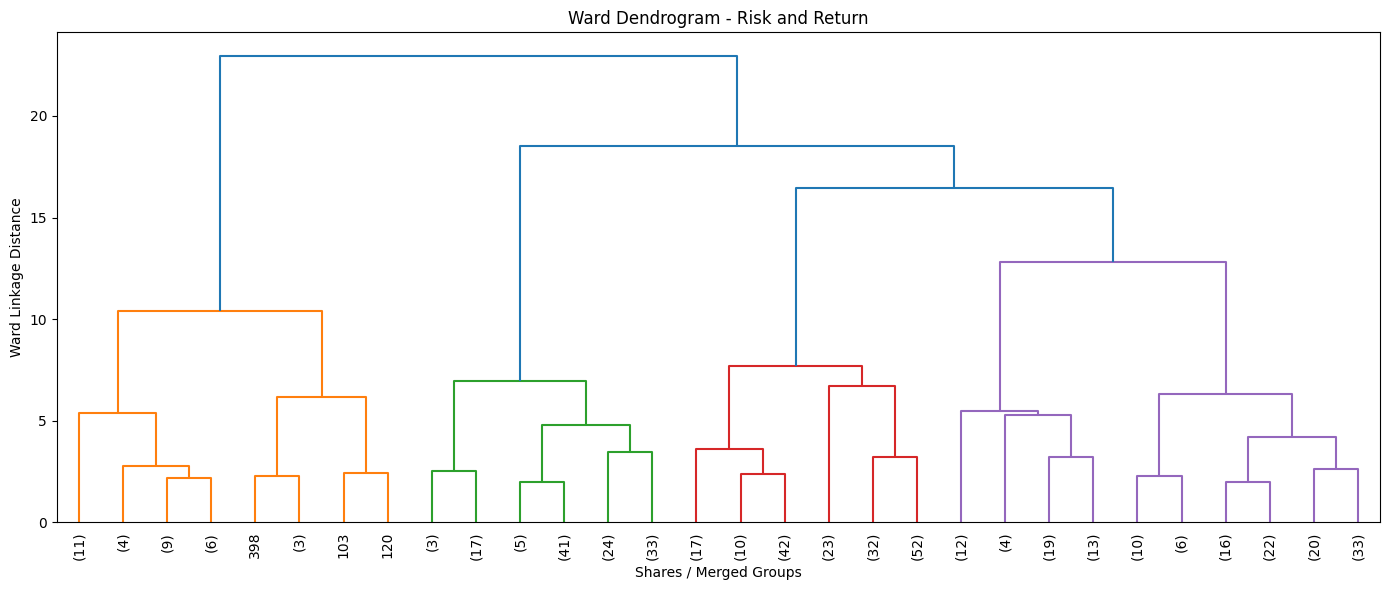

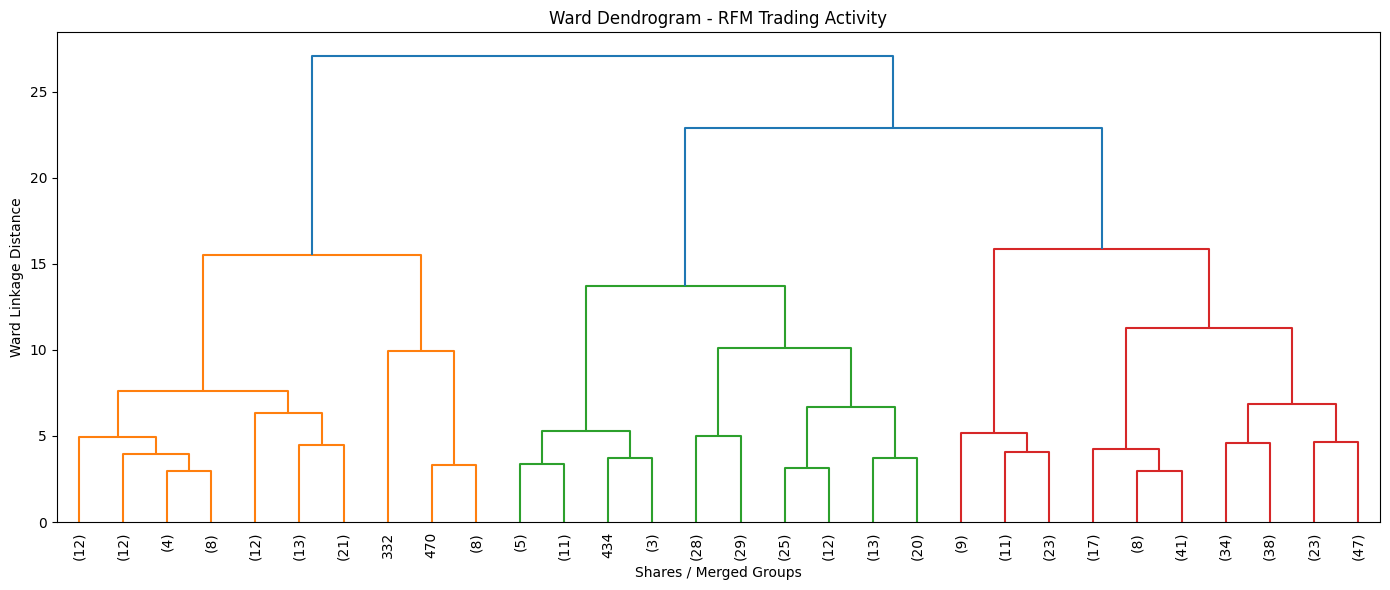

Both dendrograms created successfully!


In [83]:
#Ward Linkage and dendrograms

#Ward linkage and Euclidean distance are used.
risk_linkage = linkage(
    risk_scaled.to_numpy(),
    method="ward",
    metric="euclidean"
)

#The risk return dendrogram
plt.figure(figsize=(14, 6))

#Due to the high number of shares, the last 30 merged groups are displayed.
dendrogram(
    risk_linkage,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90
)

plt.title("Ward Dendrogram - Risk and Return")
plt.xlabel("Shares / Merged Groups")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()

plt.savefig(
    "ward_risk_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


rfm_linkage = linkage(
    rfm_scaled.to_numpy(),
    method="ward",
    metric="euclidean"
)

# RFM dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    rfm_linkage,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90
)

plt.title("Ward Dendrogram - RFM Trading Activity")
plt.xlabel("Shares / Merged Groups")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()

plt.savefig(
    "ward_rfm_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both dendrograms created successfully!")


In [84]:
#Evaluate Clusters counts 2 to 8

feature_matrices = {
    "Risk_Return": risk_scaled,
    "RFM": rfm_scaled
}


ward_results = []

#Both feature matrices are evaluated separately.
for matrix_name, X in feature_matrices.items():

    print("\nEvaluating:", matrix_name)

    for k in range(2, 9):
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )
        cluster_labels = model.fit_predict(X)

        #Silhouette score calculate
        silhouette = silhouette_score(
            X,
            cluster_labels,
            metric="euclidean"
        )

        cluster_sizes = pd.Series(
            cluster_labels
        ).value_counts().sort_index()


        ward_results.append({
            "Matrix": matrix_name,
            "K": k,
            "Silhouette_Score": silhouette,
            "Minimum_Cluster_Size": cluster_sizes.min(),
            "Maximum_Cluster_Size": cluster_sizes.max(),
            "Cluster_Sizes": cluster_sizes.tolist()
        })


        print(
            f"k={k}, "
            f"Silhouette={silhouette:.4f}, "
            f"Sizes={cluster_sizes.tolist()}"
        )

ward_comparison = pd.DataFrame(ward_results)
display(ward_comparison)
ward_comparison.to_csv(
    "ward_cluster_evaluation.csv",
    index=False
)

print("Ward cluster evaluation completed!")



Evaluating: Risk_Return
k=2, Silhouette=0.5100, Sizes=[454, 36]
k=3, Silhouette=0.2637, Sizes=[331, 36, 123]
k=4, Silhouette=0.2964, Sizes=[155, 36, 123, 176]
k=5, Silhouette=0.3244, Sizes=[36, 176, 123, 107, 48]
k=6, Silhouette=0.3280, Sizes=[176, 107, 123, 6, 48, 30]
k=7, Silhouette=0.2949, Sizes=[123, 107, 107, 6, 48, 30, 69]
k=8, Silhouette=0.2935, Sizes=[107, 107, 30, 6, 48, 103, 69, 20]

Evaluating: RFM
k=2, Silhouette=0.3586, Sizes=[398, 92]
k=3, Silhouette=0.3068, Sizes=[251, 92, 147]
k=4, Silhouette=0.2921, Sizes=[92, 208, 147, 43]
k=5, Silhouette=0.3110, Sizes=[147, 208, 10, 43, 82]
k=6, Silhouette=0.3194, Sizes=[208, 127, 10, 43, 82, 20]
k=7, Silhouette=0.2980, Sizes=[127, 82, 10, 43, 142, 20, 66]
k=8, Silhouette=0.3041, Sizes=[10, 82, 70, 43, 142, 20, 66, 57]


,Matrix,K,Silhouette_Score,Minimum_Cluster_Size,Maximum_Cluster_Size,Cluster_Sizes
0,Risk_Return,2,0.510045,36,454,"[454, 36]"
1,Risk_Return,3,0.263714,36,331,"[331, 36, 123]"
2,Risk_Return,4,0.296397,36,176,"[155, 36, 123, 176]"
3,Risk_Return,5,0.324406,36,176,"[36, 176, 123, 107, 48]"
4,Risk_Return,6,0.328010,6,176,"[176, 107, 123, 6, 48, 30]"
5,Risk_Return,7,0.294923,6,123,"[123, 107, 107, 6, 48, 30, 69]"
6,Risk_Return,8,0.293513,6,107,"[107, 107, 30, 6, 48, 103, 69, 20]"
7,RFM,2,0.358593,92,398,"[398, 92]"
8,RFM,3,0.306842,92,251,"[251, 92, 147]"
9,RFM,4,0.292052,43,208,"[92, 208, 147, 43]"


Ward cluster evaluation completed!


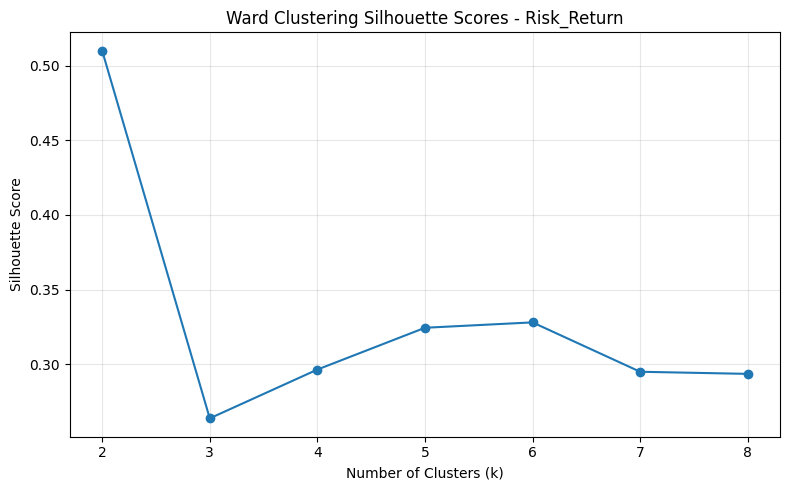

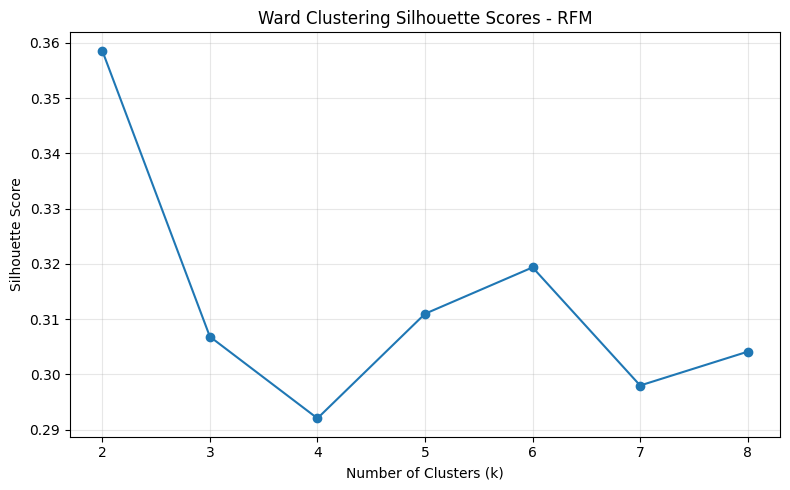

Silhouette graphs saved successfully!


In [85]:
#Silhouette score visualisations

#Create separate graphs for the two matrices
for matrix_name in ["Risk_Return", "RFM"]:
    results = ward_comparison[
        ward_comparison["Matrix"] == matrix_name
    ]
    plt.figure(figsize=(8, 5))

    plt.plot(
        results["K"],
        results["Silhouette_Score"],
        marker="o"
    )

    plt.title(
        f"Ward Clustering Silhouette Scores - {matrix_name}"
    )

    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Silhouette Score")

    plt.xticks(range(2, 9))
    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    # Graph save
    plt.savefig(
        f"ward_silhouette_{matrix_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("Silhouette graphs saved successfully!")


In [86]:
#Select candidate cluster counts

minimum_size = max(
    3,
    int(np.ceil(0.01 * len(risk_scaled)))
)

#Function for selecting the candidate cluster count
def suggest_k(matrix_name):

    #Comparison results for the relevant matrix
    results = ward_comparison[
        ward_comparison["Matrix"] == matrix_name
    ].copy()

    #Shortlist solutions that do not have very small clusters
    feasible = results[
        results["Minimum_Cluster_Size"] >= minimum_size
    ]
    if feasible.empty:
        print("Warning: All solutions contain small clusters.")
        feasible = results
    best_row = feasible.sort_values(
        "Silhouette_Score",
        ascending=False
    ).iloc[0]

    return int(best_row["K"])


#Risk return candidate cluster count
suggested_risk_k = suggest_k("Risk_Return")

#RFM candidate cluster count
suggested_rfm_k = suggest_k("RFM")

print("Suggested Risk-Return k:", suggested_risk_k)
print("Suggested RFM k:", suggested_rfm_k)
risk_k = suggested_risk_k
rfm_k = suggested_rfm_k

print("Selected Risk-Return k:", risk_k)
print("Selected RFM k:", rfm_k)


Suggested Risk-Return k: 2
Suggested RFM k: 2
Selected Risk-Return k: 2
Selected RFM k: 2


In [87]:
#Final Ward Cluster Assignments
ward_risk_model = AgglomerativeClustering(
    n_clusters=risk_k,
    linkage="ward"
)

ward_risk_labels = (
    ward_risk_model.fit_predict(risk_scaled) + 1
)

ward_rfm_model = AgglomerativeClustering(
    n_clusters=rfm_k,
    linkage="ward"
)

ward_rfm_labels = (
    ward_rfm_model.fit_predict(rfm_scaled) + 1
)

ward_assignments = pd.DataFrame({
    "Ticker": risk_scaled.index,
    "Ward_Risk_Cluster": ward_risk_labels,
    "Ward_RFM_Cluster": ward_rfm_labels
})

display(ward_assignments.head(10))
print("Risk-Return Cluster Sizes:")
print(
    ward_assignments["Ward_Risk_Cluster"]
    .value_counts()
    .sort_index()
)

print("\nRFM Cluster Sizes:")
print(
    ward_assignments["Ward_RFM_Cluster"]
    .value_counts()
    .sort_index()
)

ward_assignments.to_csv(
    "ward_cluster_assignments.csv",
    index=False
)

print("Final Ward cluster assignments saved!")


,Ticker,Ward_Risk_Cluster,Ward_RFM_Cluster
0,A,1,1
1,AAPL,1,1
2,ABBV,1,1
3,ABNB,1,1
4,ABT,1,1
5,ACGL,1,1
6,ACN,1,1
7,ADBE,1,1
8,ADI,1,2
9,ADM,1,1


Risk-Return Cluster Sizes:
Ward_Risk_Cluster
1    454
2     36
Name: count, dtype: int64

RFM Cluster Sizes:
Ward_RFM_Cluster
1    398
2     92
Name: count, dtype: int64
Final Ward cluster assignments saved!


In [88]:
#Original Unit Cluster Profiles
risk_profile_data = risk_matrix.copy()
risk_profile_data["Ward_Cluster"] = ward_risk_labels

#Calculating the average features for one cluster
risk_profiles = risk_profile_data.groupby(
    "Ward_Cluster"
).agg(
    Share_Count=("Mean_Weekly_Return", "size"),
    Mean_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Mean_Weekly_Beta=("Weekly_Beta", "mean")
).reset_index()

risk_profiles["Mean_Return_Percent"] = (
    risk_profiles["Mean_Weekly_Return"] * 100
)

print("Risk and Return Cluster Profiles:")
display(risk_profiles.round(4))

rfm_profile_data = rfm_matrix.copy()
rfm_profile_data["Ward_Cluster"] = ward_rfm_labels


rfm_profiles = rfm_profile_data.groupby(
    "Ward_Cluster"
).agg(
    Share_Count=("Recency_Days", "size"),
    Mean_Recency_Days=("Recency_Days", "mean"),
    Mean_Frequency=("Frequency", "mean"),
    Mean_Monetary_USD=("Monetary_USD", "mean"),
    Median_Monetary_USD=("Monetary_USD", "median")
).reset_index()

print("RFM Cluster Profiles:")
display(rfm_profiles.round(2))

risk_profiles.to_csv(
    "ward_risk_profiles.csv",
    index=False
)

rfm_profiles.to_csv(
    "ward_rfm_profiles.csv",
    index=False
)

ward_feature_table = common_features.merge(
    ward_assignments,
    on="Ticker",
    how="inner",
    validate="one_to_one"
)

ward_feature_table.to_csv(
    "stock_features_with_ward_clusters.csv",
    index=False
)

print("Original-unit profiles saved successfully!")


Risk and Return Cluster Profiles:


,Ward_Cluster,Share_Count,Mean_Weekly_Return,Mean_Weekly_Beta,Mean_Return_Percent
0,1,454,0.0024,0.9378,0.2410
1,2,36,0.0090,1.5189,0.9021


RFM Cluster Profiles:


,Ward_Cluster,Share_Count,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_USD,Median_Monetary_USD
0,1,398,12.33,3.21,3.842502e+10,1.556962e+10
1,2,92,55.59,2.05,4.569727e+10,2.048974e+10


Original-unit profiles saved successfully!


Task 2.3: K-Means Clustering

In [89]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
RANDOM_STATE = 42
N_INIT = 20

#First, verify the two scaled matrices.
assert risk_scaled.index.equals(rfm_scaled.index)

assert np.isfinite(risk_scaled.to_numpy()).all()
assert np.isfinite(rfm_scaled.to_numpy()).all()

if len(risk_scaled) < 9:
    raise ValueError("Insufficient shares for k=2 to 8.")

print("Risk Matrix Shape:", risk_scaled.shape)
print("RFM Matrix Shape:", rfm_scaled.shape)

print("K-Means data preparation successful!")


Risk Matrix Shape: (490, 2)
RFM Matrix Shape: (490, 3)
K-Means data preparation successful!


In [90]:
#K means model evaluations

feature_matrices = {
    "Risk_Return": risk_scaled,
    "RFM": rfm_scaled
}

kmeans_results = []


for matrix_name, X in feature_matrices.items():

    print("\nEvaluating K-Means:", matrix_name)
    for k in range(2, 9):
        kmeans = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=N_INIT,
            max_iter=300
        )
        labels = kmeans.fit_predict(X)
        silhouette = silhouette_score(
            X,
            labels,
            metric="euclidean"
        )
        inertia = kmeans.inertia_
        cluster_sizes = pd.Series(
            labels
        ).value_counts().sort_index()
        kmeans_results.append({
            "Matrix": matrix_name,
            "K": k,
            "Silhouette_Score": silhouette,
            "Inertia": inertia,
            "Minimum_Cluster_Size": int(cluster_sizes.min()),
            "Maximum_Cluster_Size": int(cluster_sizes.max()),
            "Cluster_Sizes": cluster_sizes.tolist()
        })
        print(
            f"k={k} | "
            f"Silhouette={silhouette:.4f} | "
            f"Inertia={inertia:.2f} | "
            f"Sizes={cluster_sizes.tolist()}"
        )

#Converting the results into a DataFrame
kmeans_comparison = pd.DataFrame(kmeans_results)
display(kmeans_comparison)
kmeans_comparison.to_csv(
    "kmeans_cluster_evaluation.csv",
    index=False
)

print("K-Means evaluation completed!")



Evaluating K-Means: Risk_Return
k=2 | Silhouette=0.3892 | Inertia=625.32 | Sizes=[146, 344]
k=3 | Silhouette=0.3215 | Inertia=472.21 | Sizes=[121, 165, 204]
k=4 | Silhouette=0.3241 | Inertia=372.66 | Sizes=[37, 175, 157, 121]
k=5 | Silhouette=0.3390 | Inertia=312.55 | Sizes=[129, 129, 54, 160, 18]
k=6 | Silhouette=0.3345 | Inertia=260.09 | Sizes=[106, 43, 127, 50, 157, 7]
k=7 | Silhouette=0.3365 | Inertia=224.41 | Sizes=[142, 7, 49, 81, 74, 67, 70]
k=8 | Silhouette=0.3550 | Inertia=192.38 | Sizes=[76, 40, 139, 76, 80, 7, 43, 29]

Evaluating K-Means: RFM
k=2 | Silhouette=0.4233 | Inertia=1076.99 | Sizes=[421, 69]
k=3 | Silhouette=0.3242 | Inertia=805.69 | Sizes=[153, 274, 63]
k=4 | Silhouette=0.3413 | Inertia=614.75 | Sizes=[61, 122, 93, 214]
k=5 | Silhouette=0.3575 | Inertia=519.42 | Sizes=[122, 200, 11, 89, 68]
k=6 | Silhouette=0.3459 | Inertia=440.07 | Sizes=[69, 120, 42, 142, 106, 11]
k=7 | Silhouette=0.3478 | Inertia=389.08 | Sizes=[106, 68, 120, 42, 1, 11, 142]
k=8 | Silhouette=0

,Matrix,K,Silhouette_Score,Inertia,Minimum_Cluster_Size,Maximum_Cluster_Size,Cluster_Sizes
0,Risk_Return,2,0.389168,625.324477,146,344,"[146, 344]"
1,Risk_Return,3,0.321503,472.207639,121,204,"[121, 165, 204]"
2,Risk_Return,4,0.324099,372.656806,37,175,"[37, 175, 157, 121]"
3,Risk_Return,5,0.339015,312.545316,18,160,"[129, 129, 54, 160, 18]"
4,Risk_Return,6,0.334515,260.090273,7,157,"[106, 43, 127, 50, 157, 7]"
5,Risk_Return,7,0.336535,224.413937,7,142,"[142, 7, 49, 81, 74, 67, 70]"
6,Risk_Return,8,0.354976,192.376462,7,139,"[76, 40, 139, 76, 80, 7, 43, 29]"
7,RFM,2,0.423290,1076.985441,69,421,"[421, 69]"
8,RFM,3,0.324229,805.685105,63,274,"[153, 274, 63]"
9,RFM,4,0.341252,614.746732,61,214,"[61, 122, 93, 214]"


K-Means evaluation completed!


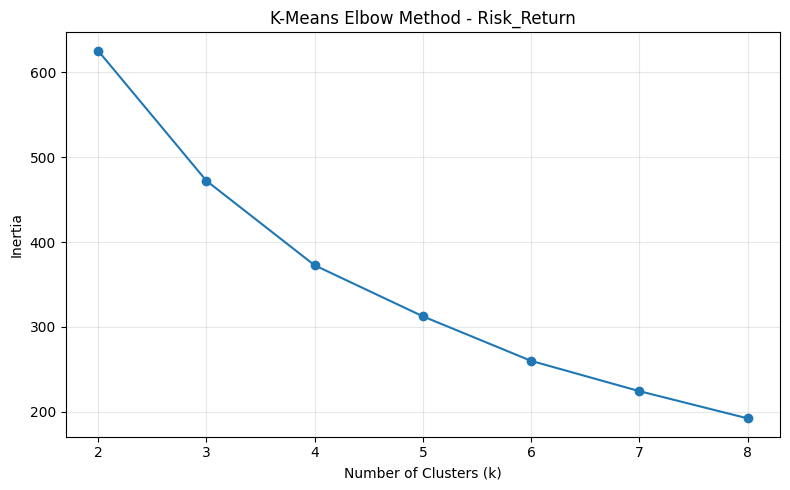

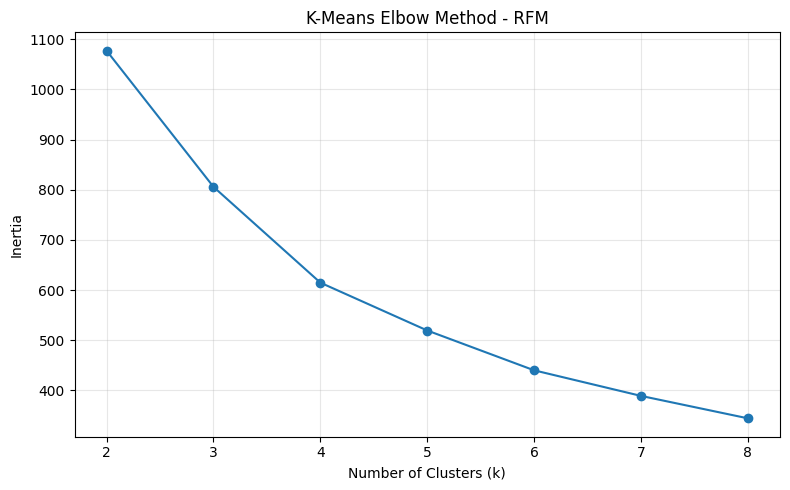

Elbow graphs saved successfully!


In [91]:
#Elbow method visualisation

#Risk Return and RFM separate elbow graphs
for matrix_name in ["Risk_Return", "RFM"]:
    results = kmeans_comparison[
        kmeans_comparison["Matrix"] == matrix_name
    ]
    plt.figure(figsize=(8, 5))
    plt.plot(
        results["K"],
        results["Inertia"],
        marker="o"
    )
    plt.title(f"K-Means Elbow Method - {matrix_name}")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")

    plt.xticks(range(2, 9))

    # Grid lines
    plt.grid(True, alpha=0.3)

    plt.tight_layout()


    plt.savefig(
        f"kmeans_elbow_{matrix_name}.png",
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

print("Elbow graphs saved successfully!")





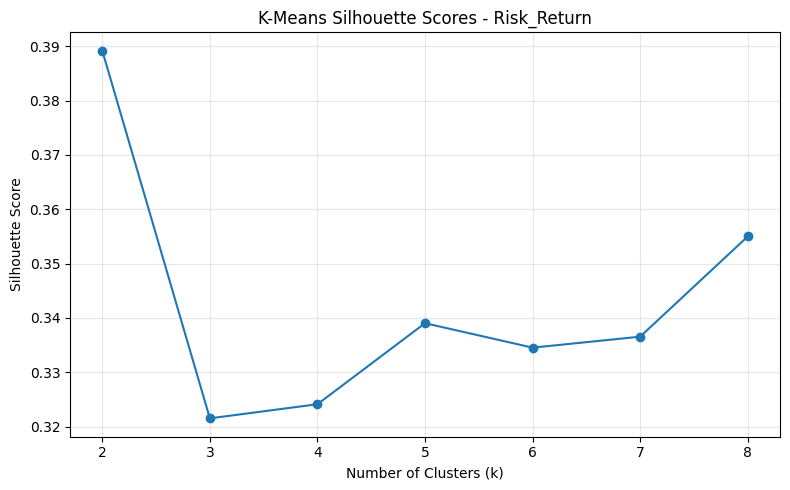

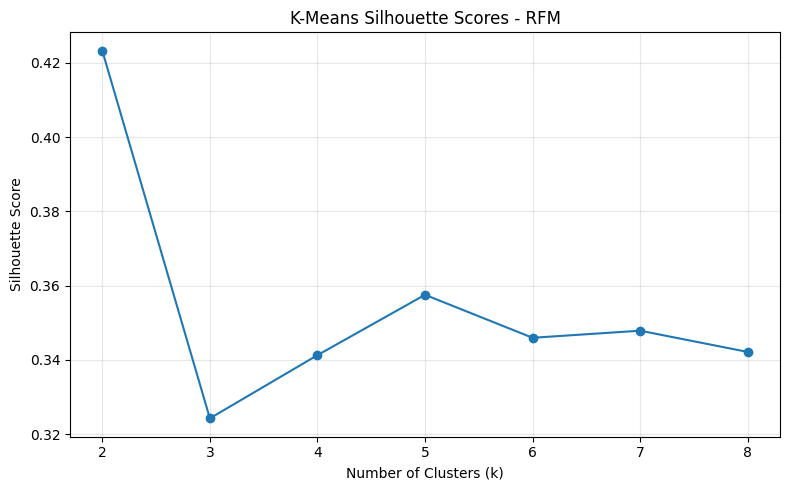

Silhouette score graphs saved!


In [92]:
#Silhouette score graphs
for matrix_name in ["Risk_Return", "RFM"]:

    results = kmeans_comparison[
        kmeans_comparison["Matrix"] == matrix_name
    ]
    plt.figure(figsize=(8, 5))

    plt.plot(
        results["K"],
        results["Silhouette_Score"],
        marker="o"
    )

    plt.title(
        f"K-Means Silhouette Scores - {matrix_name}"
    )

    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Silhouette Score")

    plt.xticks(range(2, 9))
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        f"kmeans_silhouette_{matrix_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("Silhouette score graphs saved!")


In [93]:
#Select candidate k values

minimum_cluster_size = max(
    3,
    int(np.ceil(0.01 * len(risk_scaled)))
)

# Suitable k suggest කරන function
def suggest_kmeans_k(matrix_name):

    results = kmeans_comparison[
        kmeans_comparison["Matrix"] == matrix_name
    ].copy()

    feasible = results[
        results["Minimum_Cluster_Size"] >= minimum_cluster_size
    ]

    if feasible.empty:
        print("Warning: No solution meets size threshold.")
        feasible = results

    best = feasible.sort_values(
        "Silhouette_Score",
        ascending=False
    ).iloc[0]

    return int(best["K"])

suggested_kmeans_risk_k = suggest_kmeans_k(
    "Risk_Return"
)
suggested_kmeans_rfm_k = suggest_kmeans_k(
    "RFM"
)

print("Suggested Risk-Return K:",
      suggested_kmeans_risk_k)

print("Suggested RFM K:",
      suggested_kmeans_rfm_k)

kmeans_risk_k = suggested_kmeans_risk_k
kmeans_rfm_k = suggested_kmeans_rfm_k


Suggested Risk-Return K: 2
Suggested RFM K: 2


In [94]:
#Final k meeans models
kmeans_risk_model = KMeans(
    n_clusters=kmeans_risk_k,
    random_state=RANDOM_STATE,
    n_init=N_INIT
)
kmeans_risk_labels = (
    kmeans_risk_model.fit_predict(risk_scaled) + 1
)
kmeans_rfm_model = KMeans(
    n_clusters=kmeans_rfm_k,
    random_state=RANDOM_STATE,
    n_init=N_INIT
)
kmeans_rfm_labels = (
    kmeans_rfm_model.fit_predict(rfm_scaled) + 1
)
kmeans_assignments = pd.DataFrame({
    "Ticker": risk_scaled.index,
    "KMeans_Risk_Cluster": kmeans_risk_labels,
    "KMeans_RFM_Cluster": kmeans_rfm_labels
})

display(kmeans_assignments.head(10))


print("Risk K-Means Cluster Sizes:")
print(
    kmeans_assignments["KMeans_Risk_Cluster"]
    .value_counts()
    .sort_index()
)

print("\nRFM K-Means Cluster Sizes:")
print(
    kmeans_assignments["KMeans_RFM_Cluster"]
    .value_counts()
    .sort_index()
)

kmeans_assignments.to_csv(
    "kmeans_cluster_assignments.csv",
    index=False
)

print("Final K-Means clustering completed!")


,Ticker,KMeans_Risk_Cluster,KMeans_RFM_Cluster
0,A,2,1
1,AAPL,1,1
2,ABBV,2,1
3,ABNB,1,1
4,ABT,2,1
5,ACGL,2,1
6,ACN,2,1
7,ADBE,1,1
8,ADI,2,2
9,ADM,2,1


Risk K-Means Cluster Sizes:
KMeans_Risk_Cluster
1    146
2    344
Name: count, dtype: int64

RFM K-Means Cluster Sizes:
KMeans_RFM_Cluster
1    421
2     69
Name: count, dtype: int64
Final K-Means clustering completed!


In [95]:
#K means clusters profiles
kmeans_risk_profile_data = risk_matrix.copy()

kmeans_risk_profile_data["Cluster"] = kmeans_risk_labels
kmeans_risk_profiles = (
    kmeans_risk_profile_data
    .groupby("Cluster")
    .agg(
        Share_Count=("Mean_Weekly_Return", "size"),
        Mean_Weekly_Return=("Mean_Weekly_Return", "mean"),
        Mean_Weekly_Beta=("Weekly_Beta", "mean")
    )
    .reset_index()
)
kmeans_risk_profiles["Mean_Return_Percent"] = (
    kmeans_risk_profiles["Mean_Weekly_Return"] * 100
)

print("Risk and Return K-Means Profiles:")
display(kmeans_risk_profiles.round(4))


kmeans_rfm_profile_data = rfm_matrix.copy()
kmeans_rfm_profile_data["Cluster"] = kmeans_rfm_labels
kmeans_rfm_profiles = (
    kmeans_rfm_profile_data
    .groupby("Cluster")
    .agg(
        Share_Count=("Recency_Days", "size"),
        Mean_Recency_Days=("Recency_Days", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary_USD=("Monetary_USD", "mean"),
        Median_Monetary_USD=("Monetary_USD", "median")
    )
    .reset_index()
)

print("RFM K-Means Profiles:")
display(kmeans_rfm_profiles.round(2))

kmeans_risk_profiles.to_csv(
    "kmeans_risk_profiles.csv",
    index=False
)

kmeans_rfm_profiles.to_csv(
    "kmeans_rfm_profiles.csv",
    index=False
)

print("K-Means cluster profiles saved!")


Risk and Return K-Means Profiles:


,Cluster,Share_Count,Mean_Weekly_Return,Mean_Weekly_Beta,Mean_Return_Percent
0,1,146,0.0054,1.3658,0.5408
1,2,344,0.0018,0.8169,0.1829


RFM K-Means Profiles:


,Cluster,Share_Count,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_USD,Median_Monetary_USD
0,1,421,13.46,3.19,3.276575e+10,1.565706e+10
1,2,69,63.14,1.81,8.265111e+10,2.274797e+10


K-Means cluster profiles saved!


In [96]:
#Combine all four baseline solutions
all_cluster_assignments = ward_assignments.merge(
    kmeans_assignments,
    on="Ticker",
    how="inner",
    validate="one_to_one"
)

# Original common feature table assignments join
final_feature_table = common_features.merge(
    all_cluster_assignments,
    on="Ticker",
    how="inner",
    validate="one_to_one"
)

# All four cluster columns
cluster_columns = [
    "Ward_Risk_Cluster",
    "Ward_RFM_Cluster",
    "KMeans_Risk_Cluster",
    "KMeans_RFM_Cluster"
]
assert not final_feature_table[cluster_columns].isna().any().any()
assert len(final_feature_table) == len(common_features)

# Results
print("Common Shares:", len(final_feature_table))

display(final_feature_table.head(10))

#Final feature table save
final_feature_table.to_csv(
    "all_four_clustering_solutions.csv",
    index=False
)

print("All four clustering solutions saved successfully!")
print("TASK 2.3 COMPLETED!")


Common Shares: 490


,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks,Recency_Days,Frequency,Monetary_USD,Ward_Risk_Cluster,Ward_RFM_Cluster,KMeans_Risk_Cluster,KMeans_RFM_Cluster
0,A,0.001121,1.074724,207,11,2,1.400180e+10,1,1,2,1
1,AAPL,0.003930,1.174835,207,11,2,6.233034e+11,1,1,1,1
2,ABBV,0.003749,0.425366,207,11,3,6.837054e+10,1,1,2,1
3,ABNB,0.001475,1.472709,207,11,3,3.652850e+10,1,1,1,1
4,ABT,0.000971,0.583543,207,11,1,3.523027e+10,1,1,2,1
5,ACGL,0.005289,0.586638,207,11,4,1.196213e+10,1,1,2,1
6,ACN,0.002376,1.143301,207,11,2,5.199430e+10,1,1,2,1
7,ADBE,0.000990,1.553525,207,18,3,1.030403e+11,1,1,1,1
8,ADI,0.002610,1.131968,207,36,1,3.849918e+10,1,2,2,2
9,ADM,0.001048,0.548877,207,11,3,9.529780e+09,1,1,2,1


All four clustering solutions saved successfully!
TASK 2.3 COMPLETED!


Task 2.4: Cluster Profiles and Algorithm Comparison

In [97]:
#Cluster comparison data
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)
comparison_data = final_feature_table.copy()
comparison_data = comparison_data.set_index("Ticker")
comparison_data = comparison_data.loc[
    risk_scaled.index
]

#All four cluster columns check
cluster_columns = [
    "Ward_Risk_Cluster",
    "Ward_RFM_Cluster",
    "KMeans_Risk_Cluster",
    "KMeans_RFM_Cluster"
]
assert comparison_data[cluster_columns].notna().all().all()
assert comparison_data.index.equals(risk_scaled.index)
assert comparison_data.index.equals(rfm_scaled.index)

#Return percentage
comparison_data["Mean_Return_Percent"] = (
    comparison_data["Mean_Weekly_Return"] * 100
)

display(comparison_data.head(10))
print("Total Common Shares:", len(comparison_data))
print("Comparison dataset prepared successfully!")


,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks,Recency_Days,Frequency,Monetary_USD,Ward_Risk_Cluster,Ward_RFM_Cluster,KMeans_Risk_Cluster,KMeans_RFM_Cluster,Mean_Return_Percent
Ticker,,,,,,,,,,,
A,0.001121,1.074724,207,11,2,1.400180e+10,1,1,2,1,0.112061
AAPL,0.003930,1.174835,207,11,2,6.233034e+11,1,1,1,1,0.392980
ABBV,0.003749,0.425366,207,11,3,6.837054e+10,1,1,2,1,0.374916
ABNB,0.001475,1.472709,207,11,3,3.652850e+10,1,1,1,1,0.147547
ABT,0.000971,0.583543,207,11,1,3.523027e+10,1,1,2,1,0.097134
ACGL,0.005289,0.586638,207,11,4,1.196213e+10,1,1,2,1,0.528878
ACN,0.002376,1.143301,207,11,2,5.199430e+10,1,1,2,1,0.237638
ADBE,0.000990,1.553525,207,18,3,1.030403e+11,1,1,1,1,0.099002
ADI,0.002610,1.131968,207,36,1,3.849918e+10,1,2,2,2,0.261013


Total Common Shares: 490
Comparison dataset prepared successfully!


In [98]:
#Compare original unit cluster
def create_risk_profile(cluster_column, algorithm_name):
    profile = comparison_data.groupby(
        cluster_column
    ).agg(
        Share_Count=("Mean_Weekly_Return", "size"),
        Mean_Return_Percent=("Mean_Return_Percent", "mean"),
        Mean_Weekly_Beta=("Weekly_Beta", "mean")
    ).reset_index()
    profile["Algorithm"] = algorithm_name
    profile = profile.rename(
        columns={cluster_column: "Cluster"}
    )

    return profile
ward_risk_comparison = create_risk_profile(
    "Ward_Risk_Cluster",
    "Ward"
)
kmeans_risk_comparison = create_risk_profile(
    "KMeans_Risk_Cluster",
    "K-Means"
)
risk_algorithm_profiles = pd.concat(
    [
        ward_risk_comparison,
        kmeans_risk_comparison
    ],
    ignore_index=True
)

print("Risk and Return Algorithm Profiles:")
display(risk_algorithm_profiles.round(4))
def create_rfm_profile(cluster_column, algorithm_name):

    profile = comparison_data.groupby(
        cluster_column
    ).agg(
        Share_Count=("Recency_Days", "size"),
        Mean_Recency_Days=("Recency_Days", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary_USD=("Monetary_USD", "mean"),
        Median_Monetary_USD=("Monetary_USD", "median")
    ).reset_index()

    profile["Algorithm"] = algorithm_name

    profile = profile.rename(
        columns={cluster_column: "Cluster"}
    )

    return profile
ward_rfm_comparison = create_rfm_profile(
    "Ward_RFM_Cluster",
    "Ward"
)
kmeans_rfm_comparison = create_rfm_profile(
    "KMeans_RFM_Cluster",
    "K-Means"
)
rfm_algorithm_profiles = pd.concat(
    [
        ward_rfm_comparison,
        kmeans_rfm_comparison
    ],
    ignore_index=True
)

print("RFM Algorithm Profiles:")
display(rfm_algorithm_profiles.round(2))
risk_algorithm_profiles.to_csv(
    "risk_algorithm_profiles.csv",
    index=False
)

rfm_algorithm_profiles.to_csv(
    "rfm_algorithm_profiles.csv",
    index=False
)
print("Original-unit comparison profiles saved!")


Risk and Return Algorithm Profiles:


,Cluster,Share_Count,Mean_Return_Percent,Mean_Weekly_Beta,Algorithm
0,1,454,0.2410,0.9378,Ward
1,2,36,0.9021,1.5189,Ward
2,1,146,0.5408,1.3658,K-Means
3,2,344,0.1829,0.8169,K-Means


RFM Algorithm Profiles:


,Cluster,Share_Count,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_USD,Median_Monetary_USD,Algorithm
0,1,398,12.33,3.21,3.842502e+10,1.556962e+10,Ward
1,2,92,55.59,2.05,4.569727e+10,2.048974e+10,Ward
2,1,421,13.46,3.19,3.276575e+10,1.565706e+10,K-Means
3,2,69,63.14,1.81,8.265111e+10,2.274797e+10,K-Means


Original-unit comparison profiles saved!


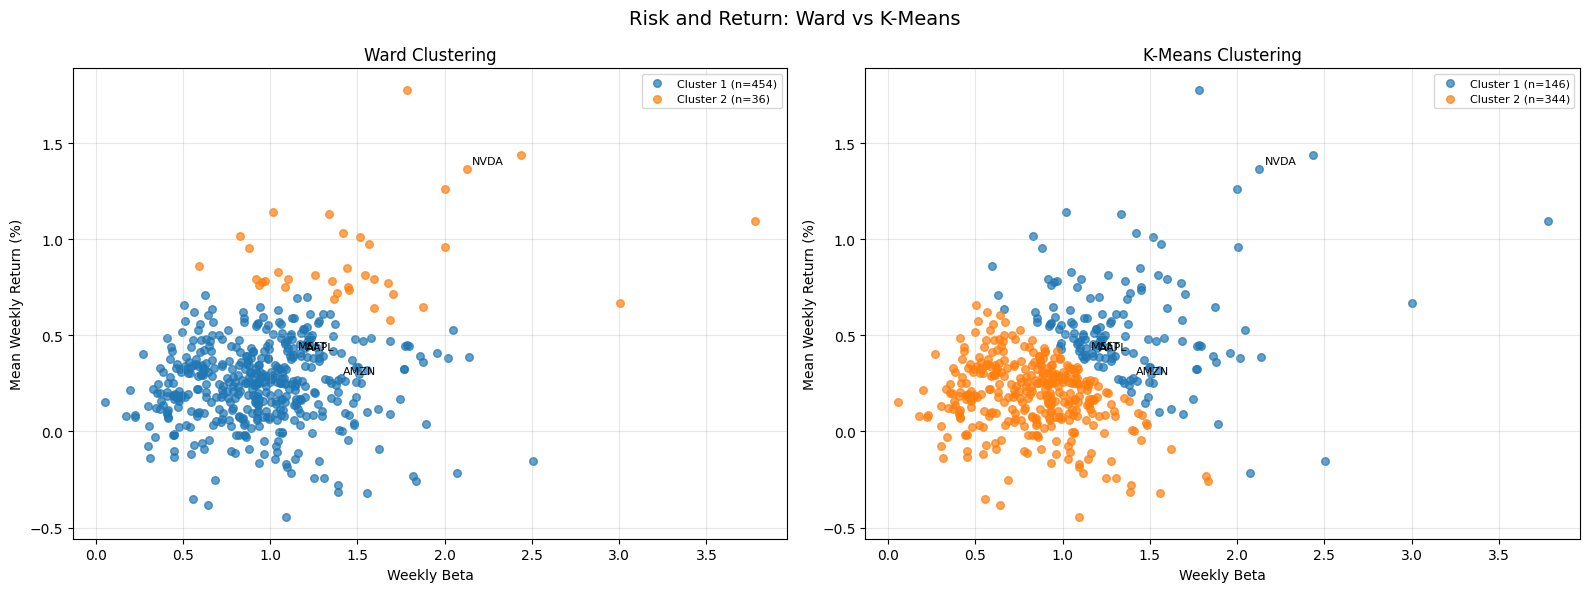

Risk and Return comparison graph saved!


In [99]:
#Risk abd return 2 d visualisation
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)
risk_plots = [
    ("Ward_Risk_Cluster", "Ward Clustering"),
    ("KMeans_Risk_Cluster", "K-Means Clustering")
]

for ax, (cluster_col, title) in zip(axes, risk_plots):
    clusters = sorted(
        comparison_data[cluster_col].unique()
    )
    for cluster in clusters:
        subset = comparison_data[
            comparison_data[cluster_col] == cluster
        ]
        ax.scatter(
            subset["Weekly_Beta"],
            subset["Mean_Return_Percent"],
            label=f"Cluster {cluster} (n={len(subset)})",
            alpha=0.7,
            s=30
        )
    for ticker in ["AAPL", "MSFT", "NVDA", "AMZN"]:

        if ticker in comparison_data.index:

            row = comparison_data.loc[ticker]

            ax.annotate(
                ticker,
                (
                    row["Weekly_Beta"],
                    row["Mean_Return_Percent"]
                ),
                fontsize=8,
                xytext=(4, 4),
                textcoords="offset points"
            )
    ax.set_title(title)
    ax.set_xlabel("Weekly Beta")
    ax.set_ylabel("Mean Weekly Return (%)")

    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
fig.suptitle(
    "Risk and Return: Ward vs K-Means",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "risk_ward_vs_kmeans.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print("Risk and Return comparison graph saved!")


In [100]:
#PCA For rfm visualisation
pca = PCA(n_components=2)
rfm_pca_values = pca.fit_transform(rfm_scaled)
rfm_pca = pd.DataFrame(
    rfm_pca_values,
    columns=["PC1", "PC2"],
    index=rfm_scaled.index
)


rfm_pca["Ward_Cluster"] = comparison_data[
    "Ward_RFM_Cluster"
]

rfm_pca["KMeans_Cluster"] = comparison_data[
    "KMeans_RFM_Cluster"
]

explained_variance = (
    pca.explained_variance_ratio_ * 100
)

print("PC1 Explained Variance:",
      round(explained_variance[0], 2), "%")

print("PC2 Explained Variance:",
      round(explained_variance[1], 2), "%")

print(
    "Total Explained Variance:",
    round(explained_variance.sum(), 2), "%"
)

pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=rfm_scaled.columns,
    columns=["PC1_Loading", "PC2_Loading"]
)

print("PCA Feature Loadings:")
display(pca_loadings.round(4))
rfm_pca.to_csv("rfm_pca_coordinates.csv")

pca_loadings.to_csv("rfm_pca_loadings.csv")

print("PCA transformation completed!")


PC1 Explained Variance: 45.63 %
PC2 Explained Variance: 33.89 %
Total Explained Variance: 79.52 %
PCA Feature Loadings:


,PC1_Loading,PC2_Loading
Recency_Days,0.7144,0.0377
Frequency,-0.6463,0.4184
Log_Monetary,0.2683,0.9075


PCA transformation completed!


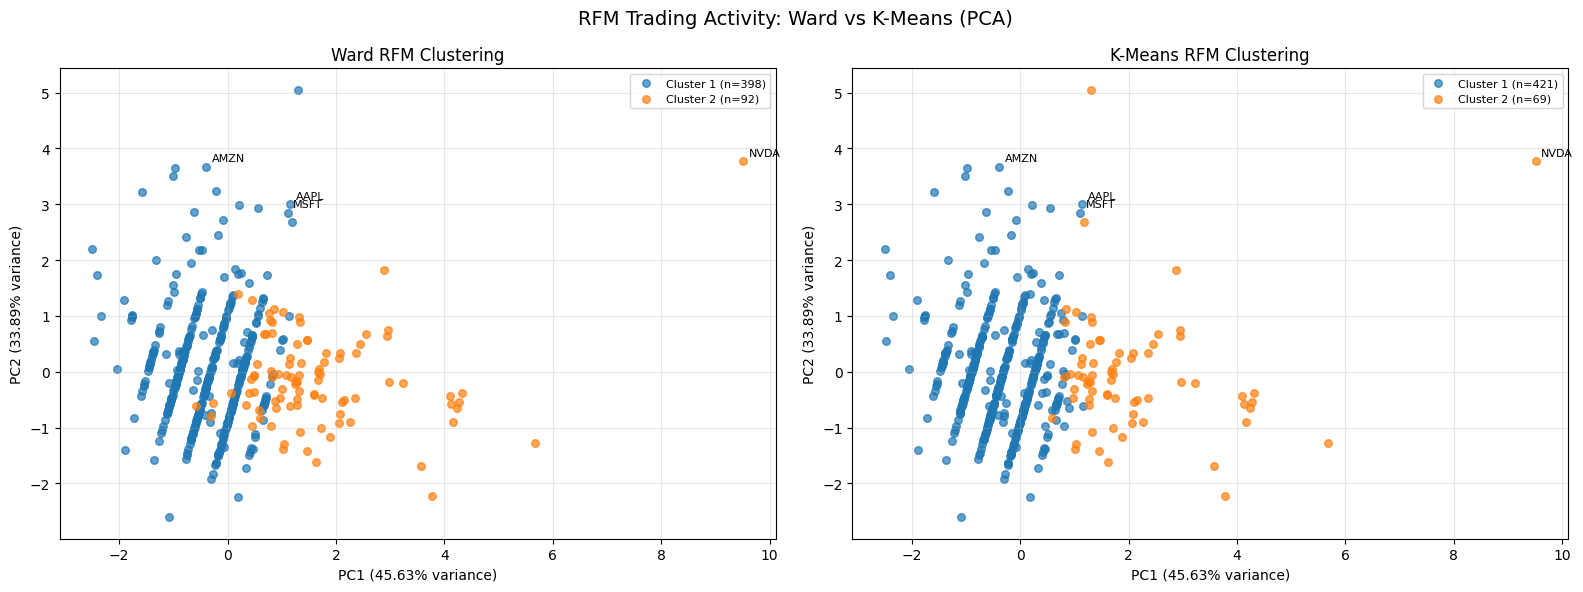

RFM PCA comparison graph saved!


In [101]:
#RFM PCA Cluster Visualization
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

# Plot specifications
rfm_plots = [
    ("Ward_Cluster", "Ward RFM Clustering"),
    ("KMeans_Cluster", "K-Means RFM Clustering")
]
for ax, (cluster_col, title) in zip(axes, rfm_plots):
    clusters = sorted(
        rfm_pca[cluster_col].unique()
    )
    for cluster in clusters:

        subset = rfm_pca[
            rfm_pca[cluster_col] == cluster
        ]

        ax.scatter(
            subset["PC1"],
            subset["PC2"],
            label=f"Cluster {cluster} (n={len(subset)})",
            alpha=0.7,
            s=30
        )
    for ticker in ["AAPL", "MSFT", "NVDA", "AMZN"]:

        if ticker in rfm_pca.index:

            row = rfm_pca.loc[ticker]

            ax.annotate(
                ticker,
                (row["PC1"], row["PC2"]),
                fontsize=8,
                xytext=(4, 4),
                textcoords="offset points"
            )
    ax.set_xlabel(
        f"PC1 ({explained_variance[0]:.2f}% variance)"
    )

    ax.set_ylabel(
        f"PC2 ({explained_variance[1]:.2f}% variance)"
    )

    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

#Figure title
fig.suptitle(
    "RFM Trading Activity: Ward vs K-Means (PCA)",
    fontsize=14
)

plt.tight_layout()

#Graph export
plt.savefig(
    "rfm_ward_vs_kmeans_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("RFM PCA comparison graph saved!")


In [102]:
#Algorithum Comparison
# Risk Ward silhouette score
ward_risk_sil = silhouette_score(
    risk_scaled,
    comparison_data["Ward_Risk_Cluster"]
)

#Risk KMeans silhouette score
kmeans_risk_sil = silhouette_score(
    risk_scaled,
    comparison_data["KMeans_Risk_Cluster"]
)

#RFM Ward silhouette score
ward_rfm_sil = silhouette_score(
    rfm_scaled,
    comparison_data["Ward_RFM_Cluster"]
)

#RFM K Means silhouette score
kmeans_rfm_sil = silhouette_score(
    rfm_scaled,
    comparison_data["KMeans_RFM_Cluster"]
)

#Risk clustering agreement calculate
risk_ari = adjusted_rand_score(
    comparison_data["Ward_Risk_Cluster"],
    comparison_data["KMeans_Risk_Cluster"]
)

# RFM clustering agreement calculate
rfm_ari = adjusted_rand_score(
    comparison_data["Ward_RFM_Cluster"],
    comparison_data["KMeans_RFM_Cluster"]
)

algorithm_comparison = pd.DataFrame([
    {
        "Feature_Matrix": "Risk_Return",
        "Ward_K": risk_k,
        "KMeans_K": kmeans_risk_k,
        "Ward_Silhouette": ward_risk_sil,
        "KMeans_Silhouette": kmeans_risk_sil,
        "Adjusted_Rand_Index": risk_ari
    },
    {
        "Feature_Matrix": "RFM",
        "Ward_K": rfm_k,
        "KMeans_K": kmeans_rfm_k,
        "Ward_Silhouette": ward_rfm_sil,
        "KMeans_Silhouette": kmeans_rfm_sil,
        "Adjusted_Rand_Index": rfm_ari
    }
])

#Results
display(algorithm_comparison.round(4))

algorithm_comparison.to_csv(
    "ward_kmeans_algorithm_comparison.csv",
    index=False
)

print("Risk ARI:", round(risk_ari, 4))
print("RFM ARI:", round(rfm_ari, 4))

print("Algorithm comparison completed!")


,Feature_Matrix,Ward_K,KMeans_K,Ward_Silhouette,KMeans_Silhouette,Adjusted_Rand_Index
0,Risk_Return,2,2,0.5100,0.3892,0.2093
1,RFM,2,2,0.3586,0.4233,0.7391


Risk ARI: 0.2093
RFM ARI: 0.7391
Algorithm comparison completed!


In [103]:
#Cluster membership compariosn
risk_membership = pd.crosstab(
    comparison_data["Ward_Risk_Cluster"],
    comparison_data["KMeans_Risk_Cluster"],
    rownames=["Ward"],
    colnames=["K-Means"]
)
rfm_membership = pd.crosstab(
    comparison_data["Ward_RFM_Cluster"],
    comparison_data["KMeans_RFM_Cluster"],
    rownames=["Ward"],
    colnames=["K-Means"]
)

print("Risk and Return Membership Comparison:")
display(risk_membership)

print("RFM Membership Comparison:")
display(rfm_membership)
risk_membership.to_csv(
    "risk_cluster_membership_comparison.csv"
)

rfm_membership.to_csv(
    "rfm_cluster_membership_comparison.csv"
)

comparison_data.to_csv(
    "task2_4_final_comparison_data.csv"
)

print("Task 2.4 completed successfully!")


Risk and Return Membership Comparison:


K-Means,1,2
Ward,,
1,110,344
2,36,0


RFM Membership Comparison:


K-Means,1,2
Ward,,
1,396,2
2,25,67


Task 2.4 completed successfully!


Task 2.5: RFM Sensitivity & Correlation Analysis

In [104]:
#RFM Correlation analysis
rfm_correlation_data = rfm_matrix[
    ["Recency_Days", "Frequency"]
].copy()

#Applying log1p transformation to 'Monetary'
#log1p(M) is required for the correlation analysis in the coursework
rfm_correlation_data["Log_Monetary"] = np.log1p(
    rfm_matrix["Monetary_USD"]
)
assert np.isfinite(
    rfm_correlation_data.to_numpy()
).all()
rfm_correlation = rfm_correlation_data.corr(
    method="pearson"
)

#Correlation results
print("RFM Pearson Correlation Matrix:")
display(rfm_correlation.round(4))

rfm_correlation.to_csv(
    "rfm_correlation_matrix.csv"
)

print("RFM correlation analysis completed!")


RFM Pearson Correlation Matrix:


,Recency_Days,Frequency,Log_Monetary
Recency_Days,1.0000,-0.3420,0.1584
Frequency,-0.3420,1.0000,0.0219
Log_Monetary,0.1584,0.0219,1.0000


RFM correlation analysis completed!


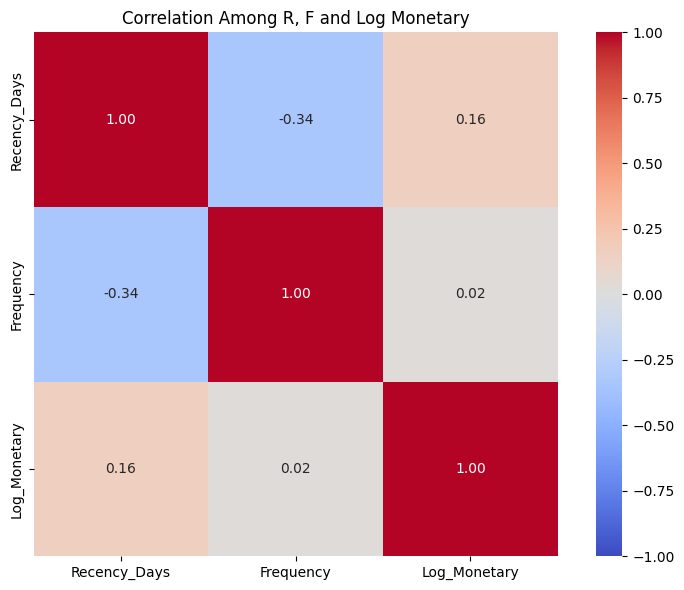

In [105]:
#RFM correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    rfm_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)
plt.title(
    "Correlation Among R, F and Log Monetary"
)

plt.tight_layout()
plt.savefig(
    "rfm_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [106]:
#Remove monetary feature
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
rf_only_matrix = rfm_matrix[
    ["Recency_Days", "Frequency"]
].copy()

assert rfm_matrix.index.equals(rfm_scaled.index)
rf_scaler = StandardScaler()
rf_scaled = pd.DataFrame(
    rf_scaler.fit_transform(rf_only_matrix),
    columns=rf_only_matrix.columns,
    index=rf_only_matrix.index
)

print("Original RFM Matrix:", rfm_scaled.shape)
print("Reduced RF Matrix:", rf_scaled.shape)
display(rf_scaled.head(10))
assert np.isfinite(rf_scaled.to_numpy()).all()
rf_scaled.to_csv(
    "rf_reduced_scaled.csv"
)

print("Monetary removed and RF features standardised!")


Original RFM Matrix: (490, 3)
Reduced RF Matrix: (490, 2)


,Recency_Days,Frequency
Ticker,,
A,-0.444230,-0.748045
AAPL,-0.444230,-0.748045
ABBV,-0.444230,0.004608
ABNB,-0.444230,0.004608
ABT,-0.444230,-1.500697
ACGL,-0.444230,0.757261
ACN,-0.444230,-0.748045
ADBE,-0.115277,0.004608
ADI,0.730601,-1.500697


Monetary removed and RF features standardised!


In [107]:
#Ward clusterign without monetary
selected_k = rfm_k

original_ward_labels = (
    ward_assignments
    .set_index("Ticker")
    .loc[rf_scaled.index, "Ward_RFM_Cluster"]
)

assert len(original_ward_labels) == len(rf_scaled)

ward_rf_model = AgglomerativeClustering(
    n_clusters=selected_k,
    linkage="ward"
)
ward_rf_labels = (
    ward_rf_model.fit_predict(rf_scaled) + 1
)

#Original and reduced clustering assignments
rf_sensitivity_assignments = pd.DataFrame({
    "Ticker": rf_scaled.index,
    "Ward_RFM_Full": original_ward_labels.to_numpy(),
    "Ward_RF_Only": ward_rf_labels,
    "Recency_Days": rfm_matrix["Recency_Days"].to_numpy(),
    "Frequency": rfm_matrix["Frequency"].to_numpy(),
    "Monetary_USD": rfm_matrix["Monetary_USD"].to_numpy()
})

#Results
print("Selected Number of Clusters:", selected_k)

display(rf_sensitivity_assignments.head(10))

#Original model cluster sizes
print("\nOriginal RFM Cluster Sizes:")
print(
    rf_sensitivity_assignments["Ward_RFM_Full"]
    .value_counts()
    .sort_index()
)

#Reduced model cluster sizes
print("\nReduced RF Cluster Sizes:")
print(
    rf_sensitivity_assignments["Ward_RF_Only"]
    .value_counts()
    .sort_index()
)

#Clustering assignments save
rf_sensitivity_assignments.to_csv(
    "rf_monetary_removal_assignments.csv",
    index=False
)

print("Ward clustering without Monetary completed!")


Selected Number of Clusters: 2


,Ticker,Ward_RFM_Full,Ward_RF_Only,Recency_Days,Frequency,Monetary_USD
0,A,1,1,11,2,1.400180e+10
1,AAPL,1,1,11,2,6.233034e+11
2,ABBV,1,1,11,3,6.837054e+10
3,ABNB,1,1,11,3,3.652850e+10
4,ABT,1,1,11,1,3.523027e+10
5,ACGL,1,1,11,4,1.196213e+10
6,ACN,1,1,11,2,5.199430e+10
7,ADBE,1,1,18,3,1.030403e+11
8,ADI,2,2,36,1,3.849918e+10
9,ADM,1,1,11,3,9.529780e+09



Original RFM Cluster Sizes:
Ward_RFM_Full
1    398
2     92
Name: count, dtype: int64

Reduced RF Cluster Sizes:
Ward_RF_Only
1    399
2     91
Name: count, dtype: int64
Ward clustering without Monetary completed!


In [108]:
#Adjust rand index comparison
from sklearn.metrics import adjusted_rand_score

#Comparing the cluster memberships from the original RFM and the reduced RF models.
rf_ari = adjusted_rand_score(
    rf_sensitivity_assignments["Ward_RFM_Full"],
    rf_sensitivity_assignments["Ward_RF_Only"]
)

#It shows the ARI result
print("Adjusted Rand Index:", round(rf_ari, 4))

#Creating a cross tabulation of cluster membership
rf_membership_table = pd.crosstab(
    rf_sensitivity_assignments["Ward_RFM_Full"],
    rf_sensitivity_assignments["Ward_RF_Only"],
    rownames=["Full RFM Ward"],
    colnames=["Reduced RF Ward"]
)
display(rf_membership_table)

rf_membership_table.to_csv(
    "rf_sensitivity_membership_table.csv"
)

rf_ari_summary = pd.DataFrame({
    "Comparison": ["Full RFM vs Reduced RF"],
    "Selected_K": [selected_k],
    "Common_Shares": [len(rf_scaled)],
    "Adjusted_Rand_Index": [rf_ari]
})

rf_ari_summary.to_csv(
    "rf_sensitivity_ari_summary.csv",
    index=False
)

print("ARI sensitivity analysis completed!")


Adjusted Rand Index: 0.9522


Reduced RF Ward,1,2
Full RFM Ward,,
1,396,2
2,3,89


ARI sensitivity analysis completed!


In [109]:
#Compare oriignal unit cluster profiles
def create_sensitivity_profile(cluster_column, model_name):
    profile = rf_sensitivity_assignments.groupby(
        cluster_column
    ).agg(
        Share_Count=("Ticker", "size"),
        Mean_Recency_Days=("Recency_Days", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary_USD=("Monetary_USD", "mean"),
        Median_Monetary_USD=("Monetary_USD", "median")
    ).reset_index()
    profile = profile.rename(
        columns={cluster_column: "Cluster"}
    )
    profile["Model"] = model_name

    return profile

full_rfm_profiles = create_sensitivity_profile(
    "Ward_RFM_Full",
    "Full RFM"
)
reduced_rf_profiles = create_sensitivity_profile(
    "Ward_RF_Only",
    "Reduced RF"
)
sensitivity_profiles = pd.concat(
    [
        full_rfm_profiles,
        reduced_rf_profiles
    ],
    ignore_index=True
)
sensitivity_profiles["Mean_Monetary_Billion_USD"] = (
    sensitivity_profiles["Mean_Monetary_USD"] / 1e9
)

sensitivity_profiles["Median_Monetary_Billion_USD"] = (
    sensitivity_profiles["Median_Monetary_USD"] / 1e9
)
display(sensitivity_profiles.round(3))
sensitivity_profiles.to_csv(
    "rfm_monetary_sensitivity_profiles.csv",
    index=False
)

print("Cluster traded value profiles saved!")


,Cluster,Share_Count,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_USD,Median_Monetary_USD,Model,Mean_Monetary_Billion_USD,Median_Monetary_Billion_USD
0,1,398,12.332,3.211,3.842502e+10,1.556962e+10,Full RFM,38.425,15.570
1,2,92,55.587,2.054,4.569727e+10,2.048974e+10,Full RFM,45.697,20.490
2,1,399,12.323,3.213,3.789622e+10,1.546400e+10,Reduced RF,37.896,15.464
3,2,91,56.099,2.033,4.809577e+10,2.084781e+10,Reduced RF,48.096,20.848


Cluster traded value profiles saved!


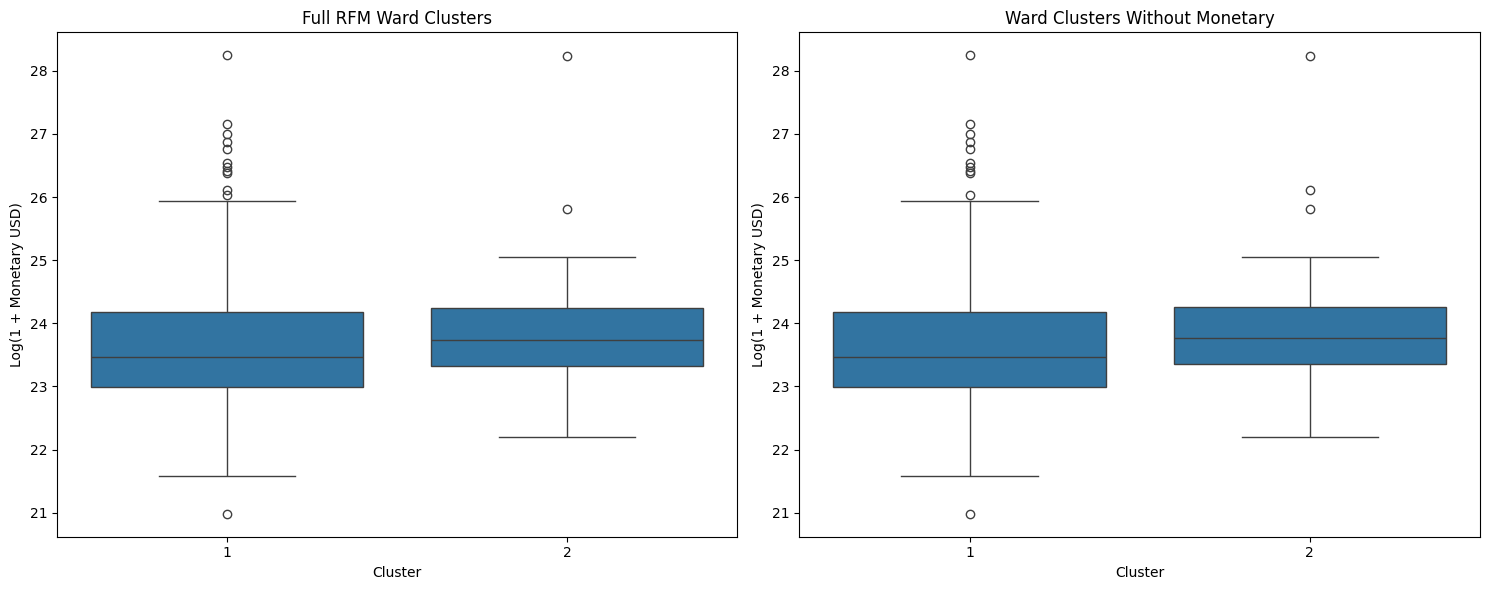

Monetary sensitivity graphs saved!


In [110]:
#Monetary sensitivity plots
plot_data = rf_sensitivity_assignments.copy()

plot_data["Log_Monetary"] = np.log1p(
    plot_data["Monetary_USD"]
)
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)
sns.boxplot(
    data=plot_data,
    x="Ward_RFM_Full",
    y="Log_Monetary",
    ax=axes[0]
)

axes[0].set_title("Full RFM Ward Clusters")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Log(1 + Monetary USD)")

#Reduced RF model graph
sns.boxplot(
    data=plot_data,
    x="Ward_RF_Only",
    y="Log_Monetary",
    ax=axes[1]
)

axes[1].set_title("Ward Clusters Without Monetary")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Log(1 + Monetary USD)")

#Overall layout
plt.tight_layout()

#Report graph save
plt.savefig(
    "monetary_removal_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Monetary sensitivity graphs saved!")


In [111]:
#Final Validation
assert len(rf_sensitivity_assignments) == len(rfm_scaled)
assert rf_scaled.shape[1] == 2
assert len(np.unique(ward_rf_labels)) == selected_k
assert original_ward_labels.nunique() == selected_k
assert rfm_correlation.shape == (3, 3)
assert np.isfinite(rf_ari)

print("Common Shares:", len(rf_scaled))
print("Selected Cluster Count:", selected_k)
print("ARI:", round(rf_ari, 4))



Common Shares: 490
Selected Cluster Count: 2
ARI: 0.9522


Task 3.2 - Cluster Profiles and Sector Composition

In [112]:
from pathlib import Path
file_path = Path("all_four_clustering_solutions.csv")
if file_path.exists():

    task3_data = pd.read_csv(file_path)

elif "final_feature_table" in globals():

    task3_data = final_feature_table.copy()
else:

    raise FileNotFoundError(
        "Task 2 results not found. "
        "Please upload all_four_clustering_solutions.csv"
    )

required_columns = [
    "Ticker",
    "Mean_Weekly_Return",
    "Weekly_Beta",
    "Recency_Days",
    "Frequency",
    "Monetary_USD",
    "Ward_Risk_Cluster",
    "Ward_RFM_Cluster",
    "KMeans_Risk_Cluster",
    "KMeans_RFM_Cluster"
]

missing_columns = [
    column for column in required_columns
    if column not in task3_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

assert not task3_data["Ticker"].duplicated().any()

print("Total Shares:", len(task3_data))

print("Dataset Shape:", task3_data.shape)
display(task3_data.head())
print("\nCluster Counts:")

for column in [
    "Ward_Risk_Cluster",
    "Ward_RFM_Cluster",
    "KMeans_Risk_Cluster",
    "KMeans_RFM_Cluster"
]:

    print(column, ":", task3_data[column].nunique())



Total Shares: 490
Dataset Shape: (490, 11)


,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks,Recency_Days,Frequency,Monetary_USD,Ward_Risk_Cluster,Ward_RFM_Cluster,KMeans_Risk_Cluster,KMeans_RFM_Cluster
0,A,0.001121,1.074724,207,11,2,1.400180e+10,1,1,2,1
1,AAPL,0.003930,1.174835,207,11,2,6.233034e+11,1,1,1,1
2,ABBV,0.003749,0.425366,207,11,3,6.837054e+10,1,1,2,1
3,ABNB,0.001475,1.472709,207,11,3,3.652850e+10,1,1,1,1
4,ABT,0.000971,0.583543,207,11,1,3.523027e+10,1,1,2,1



Cluster Counts:
Ward_Risk_Cluster : 2
Ward_RFM_Cluster : 2
KMeans_Risk_Cluster : 2
KMeans_RFM_Cluster : 2

Task 3.2 data loaded successfully!


In [113]:
#add sector information
if (
    "sp500" in globals()
    and {"Symbol", "GICS Sector"}.issubset(sp500.columns)
):

    sector_data = sp500.copy()
elif Path("sp500_tickers.csv").exists():

    sector_data = pd.read_csv("sp500_tickers.csv")

else:

    raise FileNotFoundError(
        "S&P 500 sector data not found. "
        "Run Task 1.1 or upload sp500_tickers.csv"
    )
sector_data = sector_data[
    ["Symbol", "Security", "GICS Sector"]
].copy()
sector_data["Ticker"] = (
    sector_data["Symbol"]
    .astype(str)
    .str.strip()
    .str.replace(".", "-", regex=False)
)
sector_data = sector_data.drop_duplicates(
    subset="Ticker"
)


task3_data = task3_data.drop(
    columns=["Security", "GICS Sector"],
    errors="ignore"
)

original_count = len(task3_data)
task3_data = task3_data.merge(
    sector_data[
        ["Ticker", "Security", "GICS Sector"]
    ],
    on="Ticker",
    how="left",
    validate="one_to_one"
)

assert len(task3_data) == original_count

missing_sectors = task3_data[
    "GICS Sector"
].isna().sum()

print("Missing Sector Values:", missing_sectors)
if missing_sectors > 0:

    print("Tickers with missing sectors:")

    display(
        task3_data.loc[
            task3_data["GICS Sector"].isna(),
            ["Ticker"]
        ]
    )
task3_data["GICS Sector"] = (
    task3_data["GICS Sector"].fillna("Unknown")
)

print("\nTotal Shares:", len(task3_data))

print(
    "Total Sector Categories:",
    task3_data["GICS Sector"].nunique()
)

display(
    task3_data[
        ["Ticker", "Security", "GICS Sector"]
    ].head(10)
)
print("\nShares by Sector:")

display(
    task3_data["GICS Sector"]
    .value_counts()
    .to_frame("Share_Count")
)
task3_data.to_csv(
    "task3_sector_dataset.csv",
    index=False
)

print("Sector data successfully added!")


Missing Sector Values: 0

Total Shares: 490
Total Sector Categories: 11


,Ticker,Security,GICS Sector
0,A,Agilent Technologies,Health Care
1,AAPL,Apple Inc.,Information Technology
2,ABBV,AbbVie,Health Care
3,ABNB,Airbnb,Consumer Discretionary
4,ABT,Abbott Laboratories,Health Care
5,ACGL,Arch Capital Group,Financials
6,ACN,Accenture,Information Technology
7,ADBE,Adobe Inc.,Information Technology
8,ADI,Analog Devices,Information Technology
9,ADM,Archer Daniels Midland,Consumer Staples



Shares by Sector:


,Share_Count
GICS Sector,
Industrials,79
Financials,75
Information Technology,74
Health Care,58
Consumer Discretionary,47
Consumer Staples,32
Utilities,30
Real Estate,30
Materials,23


Sector data successfully added!


In [114]:
#Sector composition analysis
cluster_models = {
    "Ward_Risk": "Ward_Risk_Cluster",
    "KMeans_Risk": "KMeans_Risk_Cluster",
    "Ward_RFM": "Ward_RFM_Cluster",
    "KMeans_RFM": "KMeans_RFM_Cluster"
}
sector_count_tables = {}
sector_percentage_tables = {}

#Analyzing all four models
for model_name, cluster_column in cluster_models.items():
    sector_counts = pd.crosstab(
        task3_data[cluster_column],
        task3_data["GICS Sector"]
    )
    sector_percentages = (
        sector_counts.div(
            sector_counts.sum(axis=1),
            axis=0
        ) * 100
    )
    sector_count_tables[model_name] = sector_counts
    sector_percentage_tables[model_name] = sector_percentages
    print("\n================================")
    print("MODEL:", model_name)
    print("================================")
    print("Sector Counts:")
    display(sector_counts)
    print("Sector Percentages (%):")
    display(sector_percentages.round(2))

    #The percentage row totals must be 100%
    assert np.allclose(
        sector_percentages.sum(axis=1),
        100
    )
    sector_counts.to_csv(
        f"sector_counts_{model_name}.csv"
    )

    sector_percentages.to_csv(
        f"sector_percentages_{model_name}.csv"
    )

print("Sector composition analysis completed!")



MODEL: Ward_Risk
Sector Counts:


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_Risk_Cluster,,,,,,,,,,,
1,20,43,32,17,70,57,72,63,22,29,29
2,1,4,0,4,5,1,7,11,1,1,1


Sector Percentages (%):


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_Risk_Cluster,,,,,,,,,,,
1,4.41,9.47,7.05,3.74,15.42,12.56,15.86,13.88,4.85,6.39,6.39
2,2.78,11.11,0.00,11.11,13.89,2.78,19.44,30.56,2.78,2.78,2.78



MODEL: KMeans_Risk
Sector Counts:


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Risk_Cluster,,,,,,,,,,,
1,6,23,1,10,18,2,29,48,4,3,2
2,15,24,31,11,57,56,50,26,19,27,28


... (7 outputs left out)

GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM_Cluster,,,,,,,,,,,
1,19,39,27,20,64,50,74,60,17,30,21
2,2,8,5,1,11,8,5,14,6,0,9


Sector Percentages (%):


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM_Cluster,,,,,,,,,,,
1,4.51,9.26,6.41,4.75,15.20,11.88,17.58,14.25,4.04,7.13,4.99
2,2.90,11.59,7.25,1.45,15.94,11.59,7.25,20.29,8.70,0.00,13.04


Sector composition analysis completed!


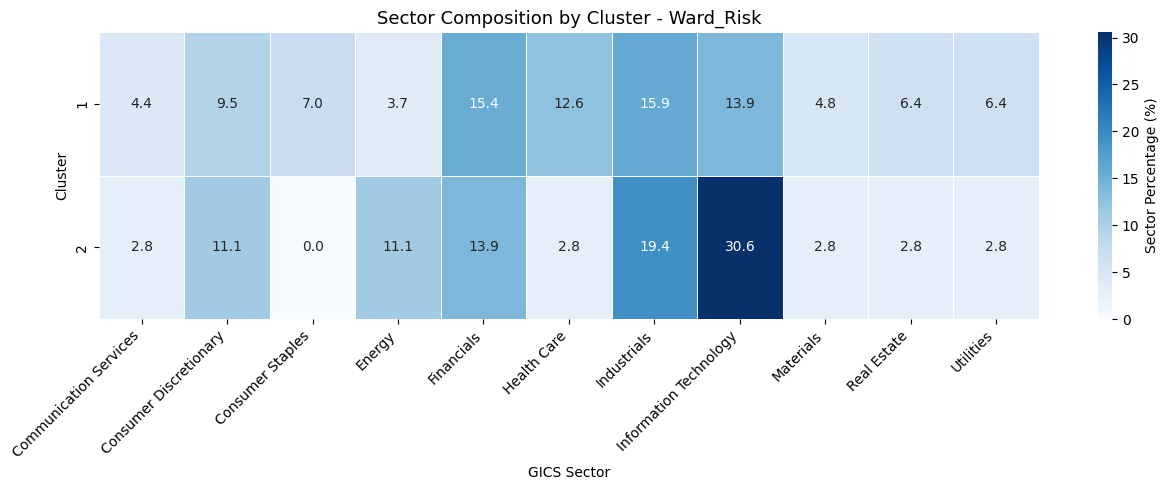

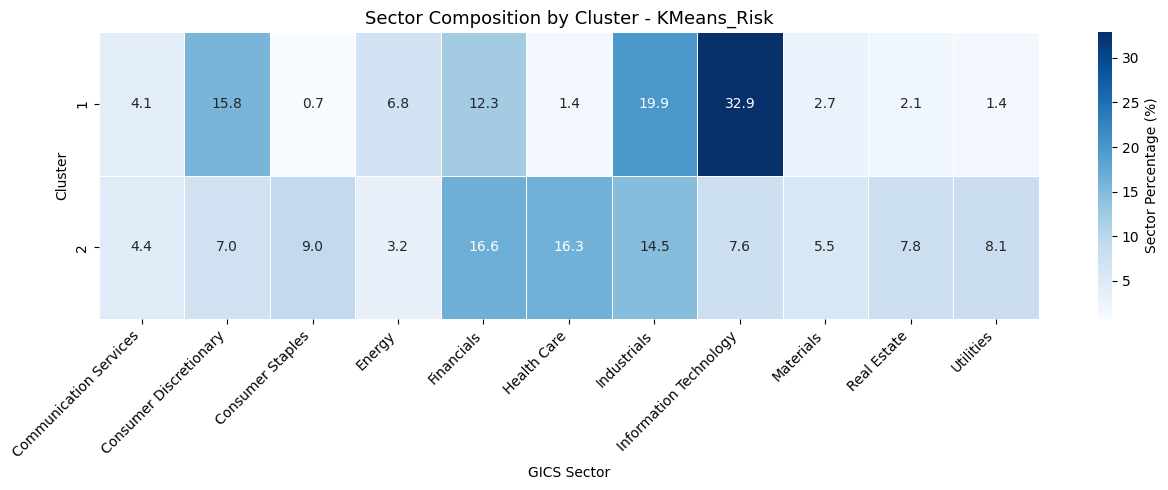

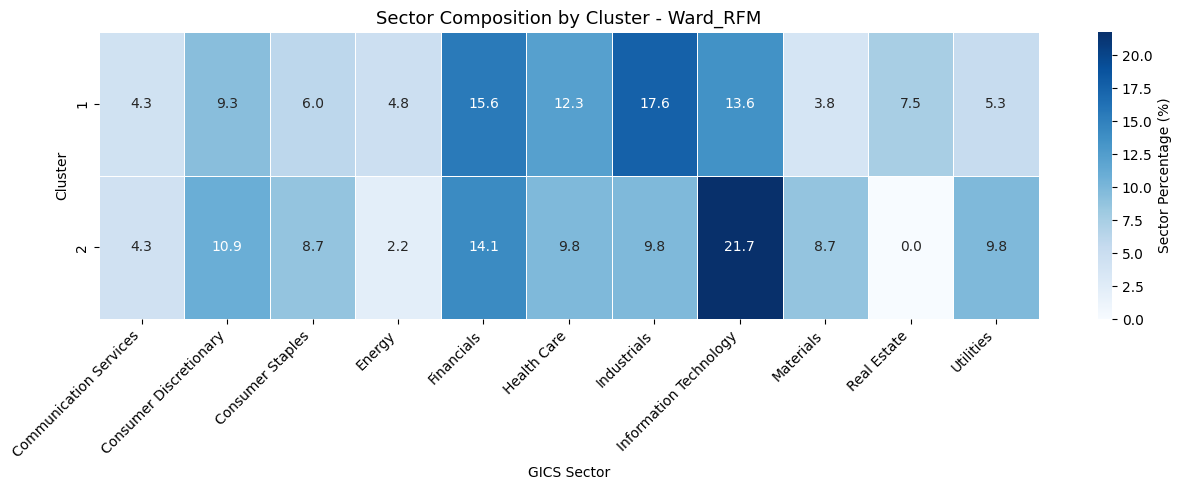

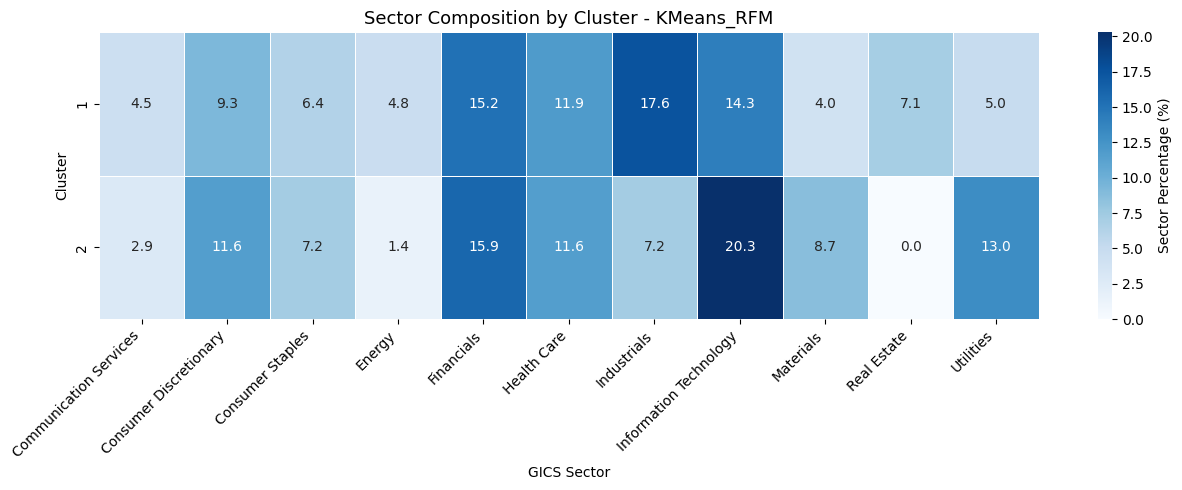

All four sector heatmaps saved successfully!


In [115]:
#Sector Composition heatmaps
for model_name, percentages in sector_percentage_tables.items():
    plt.figure(figsize=(13, 5))
    sns.heatmap(
        percentages,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        linewidths=0.5,
        cbar_kws={"label": "Sector Percentage (%)"}
    )
    plt.title(
        f"Sector Composition by Cluster - {model_name}",
        fontsize=13
    )
    plt.xlabel("GICS Sector")
    plt.ylabel("Cluster")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(
        f"sector_heatmap_{model_name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("All four sector heatmaps saved successfully!")


In [116]:
#Identify top sectors
top_sector_results = []
for model_name, percentages in sector_percentage_tables.items():
    for cluster in percentages.index:
        top_sectors = (
            percentages.loc[cluster]
            .sort_values(ascending=False)
            .head(3)
        )
        for rank, (sector, percentage) in enumerate(
            top_sectors.items(),
            start=1
        ):

            top_sector_results.append({
                "Model": model_name,
                "Cluster": cluster,
                "Rank": rank,
                "Sector": sector,
                "Percentage": percentage
            })

top_sector_summary = pd.DataFrame(
    top_sector_results
)
display(top_sector_summary.round(2))
top_sector_summary.to_csv(
    "top_sectors_by_cluster.csv",
    index=False
)



,Model,Cluster,Rank,Sector,Percentage
0,Ward_Risk,1,1,Industrials,15.86
1,Ward_Risk,1,2,Financials,15.42
2,Ward_Risk,1,3,Information Technology,13.88
3,Ward_Risk,2,1,Information Technology,30.56
4,Ward_Risk,2,2,Industrials,19.44
5,Ward_Risk,2,3,Financials,13.89
6,KMeans_Risk,1,1,Information Technology,32.88
7,KMeans_Risk,1,2,Industrials,19.86
8,KMeans_Risk,1,3,Consumer Discretionary,15.75
9,KMeans_Risk,2,1,Financials,16.57


In [117]:
#original unit cluster profiles
task3_data["Mean_Return_Percent"] = (
    task3_data["Mean_Weekly_Return"] * 100
)
cluster_models = {
    "Ward_Risk": "Ward_Risk_Cluster",
    "KMeans_Risk": "KMeans_Risk_Cluster",
    "Ward_RFM": "Ward_RFM_Cluster",
    "KMeans_RFM": "KMeans_RFM_Cluster"
}

profile_results = []
for model_name, cluster_column in cluster_models.items():
    profile = task3_data.groupby(
        cluster_column
    ).agg(
        Share_Count=("Ticker", "size"),

        Mean_Return_Percent=(
            "Mean_Return_Percent", "mean"
        ),

        Mean_Weekly_Beta=(
            "Weekly_Beta", "mean"
        ),

        Mean_Recency_Days=(
            "Recency_Days", "mean"
        ),

        Mean_Frequency=(
            "Frequency", "mean"
        ),

        Mean_Monetary_USD=(
            "Monetary_USD", "mean"
        ),

        Median_Monetary_USD=(
            "Monetary_USD", "median"
        )
    ).reset_index()
    profile = profile.rename(
        columns={cluster_column: "Cluster"}
    )
    profile["Model"] = model_name
    profile["Share_Percent"] = (
        profile["Share_Count"] /
        len(task3_data) * 100
    )
    profile["Mean_Monetary_Billion_USD"] = (
        profile["Mean_Monetary_USD"] / 1e9
    )
    profile_results.append(profile)
    print("\nMODEL:", model_name)
    display(profile.round(3))
    assert profile["Share_Count"].sum() == len(task3_data)
cluster_profiles = pd.concat(
    profile_results,
    ignore_index=True
)
cluster_profiles.to_csv(
    "task3_original_unit_cluster_profiles.csv",
    index=False
)

print("Original-unit cluster profiles completed!")



MODEL: Ward_Risk


,Cluster,Share_Count,Mean_Return_Percent,Mean_Weekly_Beta,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_USD,Median_Monetary_USD,Model,Share_Percent,Mean_Monetary_Billion_USD
0,1,454,0.241,0.938,19.855,2.967,3.427803e+10,1.593724e+10,Ward_Risk,92.653,34.278
1,2,36,0.902,1.519,28.000,3.333,1.093078e+11,2.697987e+10,Ward_Risk,7.347,109.308



MODEL: KMeans_Risk


,Cluster,Share_Count,Mean_Return_Percent,Mean_Weekly_Beta,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_USD,Median_Monetary_USD,Model,Share_Percent,Mean_Monetary_Billion_USD
0,1,146,0.541,1.366,22.740,3.164,8.201583e+10,2.563639e+10,KMeans_Risk,29.796,82.016
1,2,344,0.183,0.817,19.483,2.922,2.186918e+10,1.432196e+10,KMeans_Risk,70.204,21.869



MODEL: Ward_RFM


,Cluster,Share_Count,Mean_Return_Percent,Mean_Weekly_Beta,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_USD,Median_Monetary_USD,Model,Share_Percent,Mean_Monetary_Billion_USD
0,1,398,0.289,0.974,12.332,3.211,3.842502e+10,1.556962e+10,Ward_RFM,81.224,38.425
1,2,92,0.293,1.009,55.587,2.054,4.569727e+10,2.048974e+10,Ward_RFM,18.776,45.697



MODEL: KMeans_RFM


,Cluster,Share_Count,Mean_Return_Percent,Mean_Weekly_Beta,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_USD,Median_Monetary_USD,Model,Share_Percent,Mean_Monetary_Billion_USD
0,1,421,0.287,0.975,13.456,3.188,3.276575e+10,1.565706e+10,KMeans_RFM,85.918,32.766
1,2,69,0.308,1.012,63.145,1.812,8.265111e+10,2.274797e+10,KMeans_RFM,14.082,82.651


Original-unit cluster profiles completed!


In [118]:
#Risk vs Rfm cluster comapriosn
from sklearn.metrics import adjusted_rand_score
ward_comparison = pd.crosstab(
    task3_data["Ward_Risk_Cluster"],
    task3_data["Ward_RFM_Cluster"],
    rownames=["Ward Risk Cluster"],
    colnames=["Ward RFM Cluster"]
)
kmeans_comparison_table = pd.crosstab(
    task3_data["KMeans_Risk_Cluster"],
    task3_data["KMeans_RFM_Cluster"],
    rownames=["KMeans Risk Cluster"],
    colnames=["KMeans RFM Cluster"]
)
ward_risk_rfm_ari = adjusted_rand_score(
    task3_data["Ward_Risk_Cluster"],
    task3_data["Ward_RFM_Cluster"]
)

kmeans_risk_rfm_ari = adjusted_rand_score(
    task3_data["KMeans_Risk_Cluster"],
    task3_data["KMeans_RFM_Cluster"]
)
print("Ward Risk vs RFM:")
display(ward_comparison)

print("K-Means Risk vs RFM:")
display(kmeans_comparison_table)

print(
    "Ward Risk-RFM ARI:",
    round(ward_risk_rfm_ari, 4)
)

print(
    "K-Means Risk-RFM ARI:",
    round(kmeans_risk_rfm_ari, 4)
)
ward_comparison.to_csv(
    "ward_risk_vs_rfm_comparison.csv"
)

kmeans_comparison_table.to_csv(
    "kmeans_risk_vs_rfm_comparison.csv"
)



Ward Risk vs RFM:


Ward RFM Cluster,1,2
Ward Risk Cluster,,
1,371,83
2,27,9


K-Means Risk vs RFM:


KMeans RFM Cluster,1,2
KMeans Risk Cluster,,
1,124,22
2,297,47


Ward Risk-RFM ARI: 0.0272
K-Means Risk-RFM ARI: 0.0067


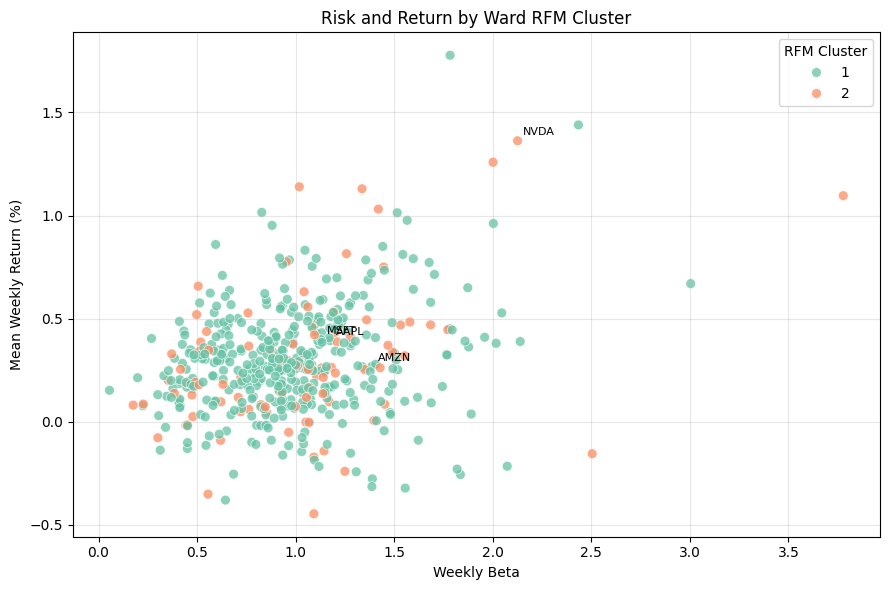

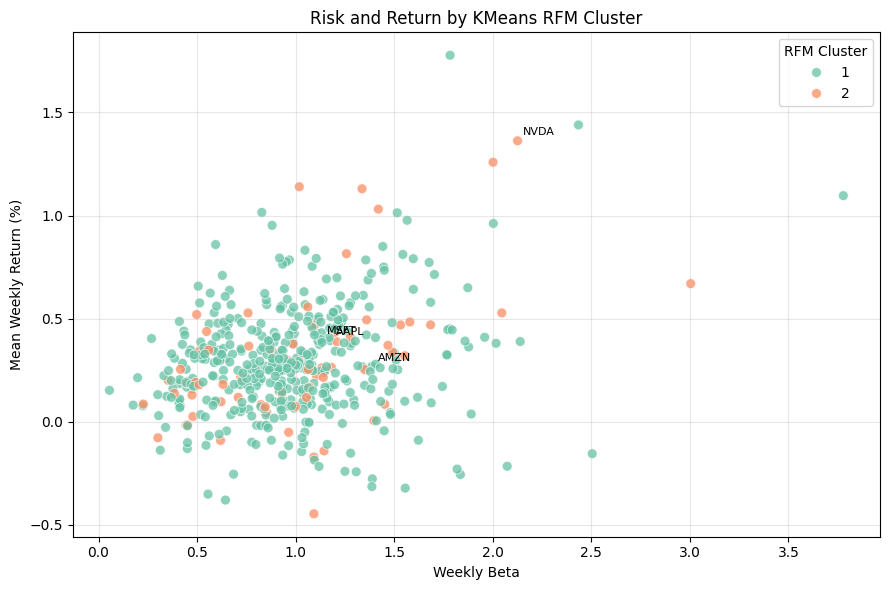

In [119]:
#Risk return vs rfm visualisation
rfm_models = {
    "Ward": "Ward_RFM_Cluster",
    "KMeans": "KMeans_RFM_Cluster"
}
for model_name, cluster_column in rfm_models.items():
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=task3_data,
        x="Weekly_Beta",
        y="Mean_Return_Percent",
        hue=cluster_column,
        palette="Set2",
        s=50,
        alpha=0.75
    )
    for ticker in ["AAPL", "MSFT", "NVDA", "AMZN"]:

        example = task3_data[
            task3_data["Ticker"] == ticker
        ]

        if not example.empty:

            row = example.iloc[0]

            plt.annotate(
                ticker,
                (
                    row["Weekly_Beta"],
                    row["Mean_Return_Percent"]
                ),
                fontsize=8,
                xytext=(4, 4),
                textcoords="offset points"
            )
    plt.title(
        f"Risk and Return by {model_name} RFM Cluster"
    )

    plt.xlabel("Weekly Beta")
    plt.ylabel("Mean Weekly Return (%)")
    plt.legend(title="RFM Cluster")

    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        f"task3_risk_return_by_{model_name}_rfm.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()



In [120]:
#final validation
assert len(cluster_models) == 4
assert set(cluster_profiles["Model"]) == set(
    cluster_models.keys()
)
print("Missing values:")
print(
    task3_data[
        [
            "Mean_Weekly_Return",
            "Weekly_Beta",
            "Recency_Days",
            "Frequency",
            "Monetary_USD"
        ]
    ].isna().sum()
)
for model_name in cluster_models:

    total = cluster_profiles.loc[
        cluster_profiles["Model"] == model_name,
        "Share_Count"
    ].sum()

    assert total == len(task3_data)
print("Total Shares:", len(task3_data))

print("Profile Records:", len(cluster_profiles))

print("Ward Risk-RFM ARI:", round(ward_risk_rfm_ari, 4))
print("KMeans Risk-RFM ARI:", round(kmeans_risk_rfm_ari, 4))



Missing values:
Mean_Weekly_Return    0
Weekly_Beta           0
Recency_Days          0
Frequency             0
Monetary_USD          0
dtype: int64
Total Shares: 490
Profile Records: 8
Ward Risk-RFM ARI: 0.0272
KMeans Risk-RFM ARI: 0.0067


Task 3.2.2 - RFM Correlation and Sensitivity Analysis

RFM Pearson Correlation Matrix:


,Recency_Days,Frequency,Log_Monetary
Recency_Days,1.0000,-0.3420,0.1584
Frequency,-0.3420,1.0000,0.0219
Log_Monetary,0.1584,0.0219,1.0000


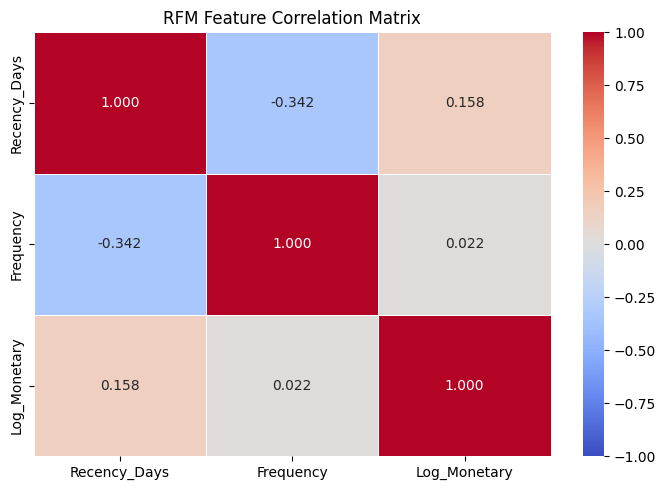

RFM correlation analysis completed!


In [121]:
#RFM feature correlation analysis
assert "task3_data" in globals()
rfm_correlation_data = task3_data[
    ["Recency_Days", "Frequency", "Monetary_USD"]
].copy()

assert rfm_correlation_data.notna().all().all()
assert (rfm_correlation_data["Monetary_USD"] >= 0).all()
rfm_correlation_data["Log_Monetary"] = np.log1p(
    rfm_correlation_data["Monetary_USD"]
)
rfm_correlation_matrix = rfm_correlation_data[
    ["Recency_Days", "Frequency", "Log_Monetary"]
].corr(method="pearson")
print("RFM Pearson Correlation Matrix:")
display(rfm_correlation_matrix.round(4))
plt.figure(figsize=(7, 5))

sns.heatmap(
    rfm_correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("RFM Feature Correlation Matrix")

plt.tight_layout()
plt.savefig(
    "task3_rfm_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
rfm_correlation_matrix.to_csv(
    "task3_rfm_correlation_matrix.csv"
)

print("RFM correlation analysis completed!")


In [122]:
#Monetary removal sensitivity test
selected_k = task3_data[
    "Ward_RFM_Cluster"
].nunique()

print("Selected Number of Clusters:", selected_k)
rf_only_data = task3_data[
    ["Recency_Days", "Frequency"]
].copy()
assert rf_only_data.notna().all().all()
rf_scaler = StandardScaler()

rf_scaled_values = rf_scaler.fit_transform(
    rf_only_data
)

rf_ward_model = AgglomerativeClustering(
    n_clusters=selected_k,
    linkage="ward",
    metric="euclidean"
)
rf_reduced_labels = rf_ward_model.fit_predict(
    rf_scaled_values
) + 1
sensitivity_results = task3_data[
    [
        "Ticker",
        "Recency_Days",
        "Frequency",
        "Monetary_USD",
        "Ward_RFM_Cluster"
    ]
].copy()
sensitivity_results = sensitivity_results.rename(
    columns={
        "Ward_RFM_Cluster": "Full_RFM_Cluster"
    }
)
sensitivity_results["Reduced_RF_Cluster"] = (
    rf_reduced_labels
)
assert len(sensitivity_results) == len(task3_data)
rf_sensitivity_ari = adjusted_rand_score(
    sensitivity_results["Full_RFM_Cluster"],
    sensitivity_results["Reduced_RF_Cluster"]
)
membership_table = pd.crosstab(
    sensitivity_results["Full_RFM_Cluster"],
    sensitivity_results["Reduced_RF_Cluster"],
    rownames=["Full RFM"],
    colnames=["Reduced RF"]
)
print("Full RFM vs Reduced RF Memberships:")
display(membership_table)

print(
    "Adjusted Rand Index (ARI):",
    round(rf_sensitivity_ari, 4)
)
sensitivity_results.to_csv(
    "task3_monetary_removal_assignments.csv",
    index=False
)

membership_table.to_csv(
    "task3_monetary_removal_membership_table.csv"
)

print("Monetary removal sensitivity test completed!")


Selected Number of Clusters: 2
Full RFM vs Reduced RF Memberships:


Reduced RF,1,2
Full RFM,,
1,396,2
2,3,89


Adjusted Rand Index (ARI): 0.9522
Monetary removal sensitivity test completed!


In [124]:
sensitivity_profiles = []
for model_name, cluster_column in [
    ("Full RFM", "Full_RFM_Cluster"),
    ("Reduced RF", "Reduced_RF_Cluster")
]:
    profile = sensitivity_results.groupby(
        cluster_column
    ).agg(
        Share_Count=("Ticker", "size"),
        Mean_Recency_Days=("Recency_Days", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary_USD=("Monetary_USD", "mean"),
        Median_Monetary_USD=("Monetary_USD", "median")
    ).reset_index()
    profile = profile.rename(
        columns={cluster_column: "Cluster"}
    )
    profile["Model"] = model_name
    profile["Mean_Monetary_Billion_USD"] = (
        profile["Mean_Monetary_USD"] / 1e9
    )

    profile["Median_Monetary_Billion_USD"] = (
        profile["Median_Monetary_USD"] / 1e9
    )
    sensitivity_profiles.append(profile)
sensitivity_profile_table = pd.concat(
    sensitivity_profiles,
    ignore_index=True
)
display(
    sensitivity_profile_table[
        [
            "Model",
            "Cluster",
            "Share_Count",
            "Mean_Recency_Days",
            "Mean_Frequency",
            "Mean_Monetary_Billion_USD",
            "Median_Monetary_Billion_USD"
        ]
    ].round(3)
)
sensitivity_profile_table.to_csv(
    "task3_monetary_sensitivity_profiles.csv",
    index=False
)

print("Monetary sensitivity profiles completed!")


,Model,Cluster,Share_Count,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_Billion_USD,Median_Monetary_Billion_USD
0,Full RFM,1,398,12.332,3.211,38.425,15.570
1,Full RFM,2,92,55.587,2.054,45.697,20.490
2,Reduced RF,1,399,12.323,3.213,37.896,15.464
3,Reduced RF,2,91,56.099,2.033,48.096,20.848


Monetary sensitivity profiles completed!


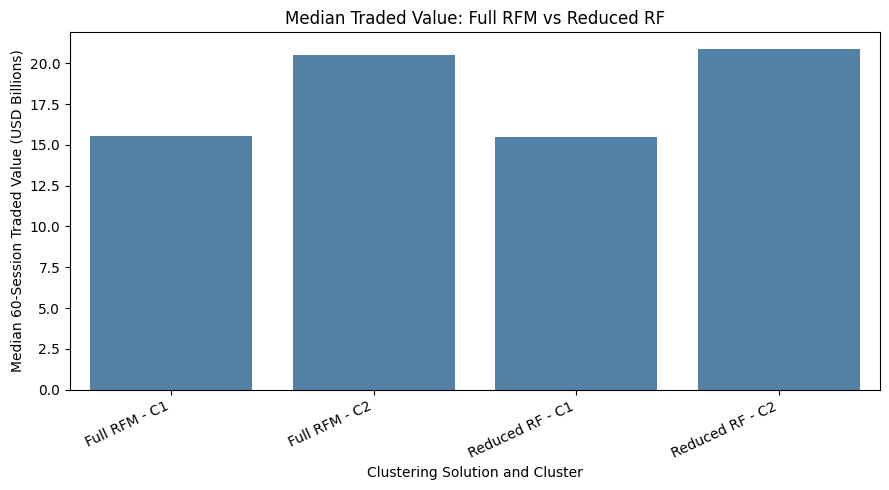

Sensitivity comparison graph saved!


In [125]:
#Monetary sensitivity visualisation
plot_data = sensitivity_profile_table[
    [
        "Model",
        "Cluster",
        "Median_Monetary_Billion_USD"
    ]
].copy()
plot_data["Group"] = (
    plot_data["Model"]
    + " - C"
    + plot_data["Cluster"].astype(str)
)
plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="Group",
    y="Median_Monetary_Billion_USD",
    color="steelblue"
)
plt.title(
    "Median Traded Value: Full RFM vs Reduced RF"
)

plt.xlabel("Clustering Solution and Cluster")
plt.ylabel("Median 60-Session Traded Value (USD Billions)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.savefig(
    "task3_monetary_sensitivity_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Sensitivity comparison graph saved!")


In [126]:
#Sensitiviry analysis validation
assert len(sensitivity_results) == 490
assert (
    sensitivity_results["Full_RFM_Cluster"].nunique()
    == selected_k
)

assert (
    sensitivity_results["Reduced_RF_Cluster"].nunique()
    == selected_k
)
assert membership_table.to_numpy().sum() == 490
assert sensitivity_results.notna().all().all()
print("Total Shares:", len(sensitivity_results))
print("Selected k:", selected_k)
print("Monetary Removal ARI:", round(rf_sensitivity_ari, 4))

print("\nRFM Correlation Matrix:")
display(rfm_correlation_matrix.round(3))

print("\nSensitivity Membership Table:")
display(membership_table)

print("\nTASK 3.2.2 SENSITIVITY ANALYSIS COMPLETED!")


Total Shares: 490
Selected k: 2
Monetary Removal ARI: 0.9522

RFM Correlation Matrix:


,Recency_Days,Frequency,Log_Monetary
Recency_Days,1.000,-0.342,0.158
Frequency,-0.342,1.000,0.022
Log_Monetary,0.158,0.022,1.000



Sensitivity Membership Table:


Reduced RF,1,2
Full RFM,,
1,396,2
2,3,89



TASK 3.2.2 SENSITIVITY ANALYSIS COMPLETED!


In [127]:
#task 3 verification
print("===== DATASET VERIFICATION =====")

print("Total Shares:", len(task3_data))
assert task3_data["Ticker"].is_unique
for model_name, cluster_column in cluster_models.items():

    print(
        model_name,
        "Clusters:",
        task3_data[cluster_column].nunique()
    )

print("\n===== CLUSTER PROFILES =====")
display(
    cluster_profiles[
        [
            "Model",
            "Cluster",
            "Share_Count",
            "Mean_Return_Percent",
            "Mean_Weekly_Beta",
            "Mean_Recency_Days",
            "Mean_Frequency",
            "Mean_Monetary_Billion_USD"
        ]
    ].round(3)
)

print("\n===== RFM CORRELATIONS =====")

display(rfm_correlation_matrix.round(3))

print("\n===== MONETARY SENSITIVITY =====")

print(
    "Adjusted Rand Index:",
    round(rf_sensitivity_ari, 4)
)

display(membership_table)

print("\n===== SAVED EVIDENCE FILES =====")

required_files = [
    "task3_original_unit_cluster_profiles.csv",
    "sector_heatmap_Ward_Risk.png",
    "sector_heatmap_Ward_RFM.png",
    "task3_rfm_correlation_heatmap.png",
    "task3_monetary_removal_assignments.csv",
    "task3_monetary_sensitivity_profiles.csv"
]
missing_files = []

for filename in required_files:

    if Path(filename).exists():
        print("OK:", filename)

    else:
        print("MISSING:", filename)
        missing_files.append(filename)

if len(missing_files) == 0:

    print("\nTASK 3 EVIDENCE FILES VERIFIED!")

else:

    print(
        "\nMissing files:",
        missing_files
    )


===== DATASET VERIFICATION =====
Total Shares: 490
Ward_Risk Clusters: 2
KMeans_Risk Clusters: 2
Ward_RFM Clusters: 2
KMeans_RFM Clusters: 2

===== CLUSTER PROFILES =====


,Model,Cluster,Share_Count,Mean_Return_Percent,Mean_Weekly_Beta,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_Billion_USD
0,Ward_Risk,1,454,0.241,0.938,19.855,2.967,34.278
1,Ward_Risk,2,36,0.902,1.519,28.000,3.333,109.308
2,KMeans_Risk,1,146,0.541,1.366,22.740,3.164,82.016
3,KMeans_Risk,2,344,0.183,0.817,19.483,2.922,21.869
4,Ward_RFM,1,398,0.289,0.974,12.332,3.211,38.425
5,Ward_RFM,2,92,0.293,1.009,55.587,2.054,45.697
6,KMeans_RFM,1,421,0.287,0.975,13.456,3.188,32.766
7,KMeans_RFM,2,69,0.308,1.012,63.145,1.812,82.651



===== RFM CORRELATIONS =====


,Recency_Days,Frequency,Log_Monetary
Recency_Days,1.000,-0.342,0.158
Frequency,-0.342,1.000,0.022
Log_Monetary,0.158,0.022,1.000



===== MONETARY SENSITIVITY =====
Adjusted Rand Index: 0.9522


Reduced RF,1,2
Full RFM,,
1,396,2
2,3,89



===== SAVED EVIDENCE FILES =====
OK: task3_original_unit_cluster_profiles.csv
OK: sector_heatmap_Ward_Risk.png
OK: sector_heatmap_Ward_RFM.png
OK: task3_rfm_correlation_heatmap.png
OK: task3_monetary_removal_assignments.csv
OK: task3_monetary_sensitivity_profiles.csv

TASK 3 EVIDENCE FILES VERIFIED!
